# Stage 1: Business Question

**Objective:** Build and compare three different models — LSTM, Transformer, and Prophet — to predict weather conditions (temperature) using historical meteorological data.

**Key Questions:**
1. Can we accurately forecast temperature using past weather patterns?
2. How do deep learning models (LSTM, Transformer) compare against a statistical model (Prophet)?
3. Does hyperparameter tuning significantly improve deep learning accuracy?
4. What is the prediction accuracy for short-term (7-day) temperature forecasting?

**Data Source:** [Open-Meteo API](https://open-meteo.com/) — free, no API key required, provides historical and forecast weather data.

**Location:** Berlin, Germany (52.52°N, 13.405°E)

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import requests
from datetime import datetime, timedelta
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout, Bidirectional
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau
import warnings
warnings.filterwarnings('ignore')

print(f"TensorFlow version: {tf.__version__}")
print(f"NumPy version: {np.__version__}")
print(f"Pandas version: {pd.__version__}")

TensorFlow version: 2.21.0
NumPy version: 2.5.3
Pandas version: 3.0.6


# Stage 2: Data Collection

We fetch **2 years of historical daily weather data** from the Open-Meteo API for **Berlin, Germany**.

**Features collected:**
- Temperature (max, min, mean)
- Precipitation sum
- Wind speed max
- Relative humidity (max, min, mean)
- Shortwave radiation (solar energy)
- Evapotranspiration

In [2]:
def fetch_weather_data(latitude=52.52, longitude=13.405, city_name="Berlin"):
    """Fetch historical weather data from Open-Meteo API."""
    end_date = datetime.now() - timedelta(days=1)
    start_date = end_date - timedelta(days=(365*5))  # 5 years

    url = "https://archive-api.open-meteo.com/v1/archive"
    params = {
        "latitude": latitude,
        "longitude": longitude,
        "start_date": start_date.strftime("%Y-%m-%d"),
        "end_date": end_date.strftime("%Y-%m-%d"),
        "daily": [
            "temperature_2m_max",
            "temperature_2m_min",
            "temperature_2m_mean",
            "precipitation_sum",
            "windspeed_10m_max",
            "shortwave_radiation_sum",
            "et0_fao_evapotranspiration",
            "relative_humidity_2m_max",
            "relative_humidity_2m_min",
            "relative_humidity_2m_mean"
        ],
        "timezone": "Europe/Berlin"
    }

    print(f"Fetching weather data for {city_name} ({latitude}, {longitude})...")
    print(f"Date range: {start_date.strftime('%Y-%m-%d')} to {end_date.strftime('%Y-%m-%d')}")

    response = requests.get(url, params=params)
    response.raise_for_status()
    data = response.json()

    daily = data["daily"]
    df = pd.DataFrame({
        "date": pd.to_datetime(daily["time"]),
        "temp_max": daily["temperature_2m_max"],
        "temp_min": daily["temperature_2m_min"],
        "temp_mean": daily["temperature_2m_mean"],
        "precipitation": daily["precipitation_sum"],
        "wind_speed_max": daily["windspeed_10m_max"],
        "radiation": daily["shortwave_radiation_sum"],
        "evapotranspiration": daily["et0_fao_evapotranspiration"],
        "humidity_max": daily["relative_humidity_2m_max"],
        "humidity_min": daily["relative_humidity_2m_min"],
        "humidity_mean": daily["relative_humidity_2m_mean"]
    })
    df.set_index("date", inplace=True)

    print(f"\nSuccessfully fetched {len(df)} days of weather data!")
    print(f"Date range: {df.index.min().date()} to {df.index.max().date()}")
    return df

df = fetch_weather_data()
df.head(10)

Fetching weather data for Berlin (52.52, 13.405)...
Date range: 2021-09-28 to 2026-09-27

Successfully fetched 1826 days of weather data!
Date range: 2021-09-28 to 2026-09-27


,temp_max,temp_min,temp_mean,precipitation,wind_speed_max,radiation,evapotranspiration,humidity_max,humidity_min,humidity_mean
date,,,,,,,,,,
2021-09-28,17.2,12.2,15.5,1.1,16.1,6.83,1.29,94,66,85
2021-09-29,16.4,11.5,13.8,9.3,18.3,4.03,0.85,100,75,90
2021-09-30,14.6,9.3,11.5,0.9,24.7,9.54,2.01,83,57,71
2021-10-01,17.6,7.7,12.2,0.0,18.5,12.05,2.57,78,44,64
2021-10-02,19.5,9.2,14.1,0.0,19.8,11.25,2.31,85,54,72
2021-10-03,21.8,14.5,17.5,0.0,22.8,7.33,3.01,76,55,62
2021-10-04,17.4,11.6,14.7,1.4,13.0,2.66,0.88,91,66,83
2021-10-05,15.7,11.0,12.9,10.8,17.6,2.20,0.52,96,86,92
2021-10-06,16.0,8.5,12.4,0.1,14.5,8.35,1.38,94,61,83


# Stage 3: Data Insights

Exploratory Data Analysis (EDA) to understand the weather patterns, distributions, and correlations in our dataset.

In [3]:
# Dataset overview
print("=" * 60)
print("DATASET OVERVIEW")
print("=" * 60)
print(f"\nShape: {df.shape}")
print(f"\nData Types:\n{df.dtypes}")
print(f"\nStatistical Summary:")
df.describe().round(2)

DATASET OVERVIEW

Shape: (1826, 10)

Data Types:
temp_max              float64
temp_min              float64
temp_mean             float64
precipitation         float64
wind_speed_max        float64
radiation             float64
evapotranspiration    float64
humidity_max            int64
humidity_min            int64
humidity_mean           int64
dtype: object

Statistical Summary:


,temp_max,temp_min,temp_mean,precipitation,wind_speed_max,radiation,evapotranspiration,humidity_max,humidity_min,humidity_mean
count,1826.00,1826.00,1826.00,1826.00,1826.00,1826.00,1826.00,1826.00,1826.00,1826.00
mean,15.00,7.13,11.01,1.72,18.44,11.76,2.31,89.67,56.83,74.26
std,8.80,6.92,7.74,3.51,6.72,8.23,1.79,8.92,18.37,13.72
min,-7.40,-13.30,-8.70,0.00,4.60,0.29,0.11,48.00,11.00,28.00
25%,8.00,1.80,5.20,0.00,13.50,3.85,0.70,86.00,42.00,65.00
50%,14.95,7.10,10.70,0.20,17.50,10.94,1.85,92.00,56.00,76.00
75%,21.80,13.00,17.58,1.80,22.40,18.67,3.72,96.00,72.00,85.00
max,39.80,27.50,32.90,44.30,49.70,29.57,8.01,100.00,96.00,99.00


In [4]:
# Missing values check
print("Missing Values:")
print(df.isnull().sum())
print(f"\nTotal missing: {df.isnull().sum().sum()}")

Missing Values:
temp_max              0
temp_min              0
temp_mean             0
precipitation         0
wind_speed_max        0
radiation             0
evapotranspiration    0
humidity_max          0
humidity_min          0
humidity_mean         0
dtype: int64

Total missing: 0


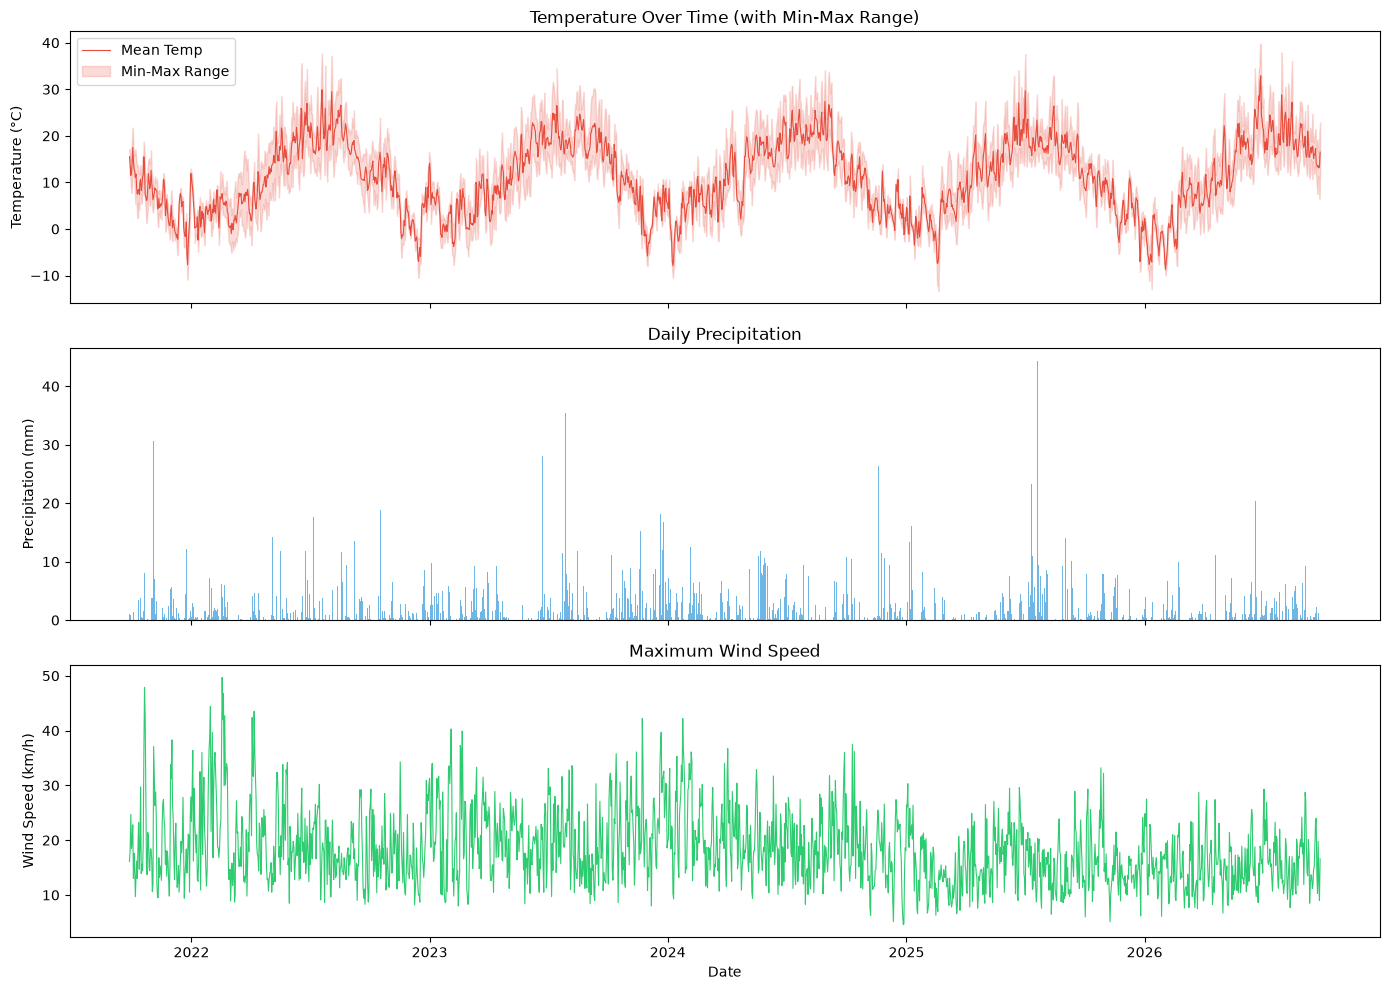

In [5]:
# Visualization 1: Temperature trends over time
fig, axes = plt.subplots(3, 1, figsize=(14, 10), sharex=True)

axes[0].plot(df.index, df['temp_mean'], color='#e74c3c', linewidth=0.8)
axes[0].fill_between(df.index, df['temp_min'], df['temp_max'], alpha=0.2, color='#e74c3c')
axes[0].set_ylabel('Temperature (°C)')
axes[0].set_title('Temperature Over Time (with Min-Max Range)')
axes[0].legend(['Mean Temp', 'Min-Max Range'])

axes[1].bar(df.index, df['precipitation'], color='#3498db', width=1.0, alpha=0.7)
axes[1].set_ylabel('Precipitation (mm)')
axes[1].set_title('Daily Precipitation')

axes[2].plot(df.index, df['wind_speed_max'], color='#2ecc71', linewidth=0.8)
axes[2].set_ylabel('Wind Speed (km/h)')
axes[2].set_title('Maximum Wind Speed')
axes[2].set_xlabel('Date')

plt.tight_layout()
plt.show()

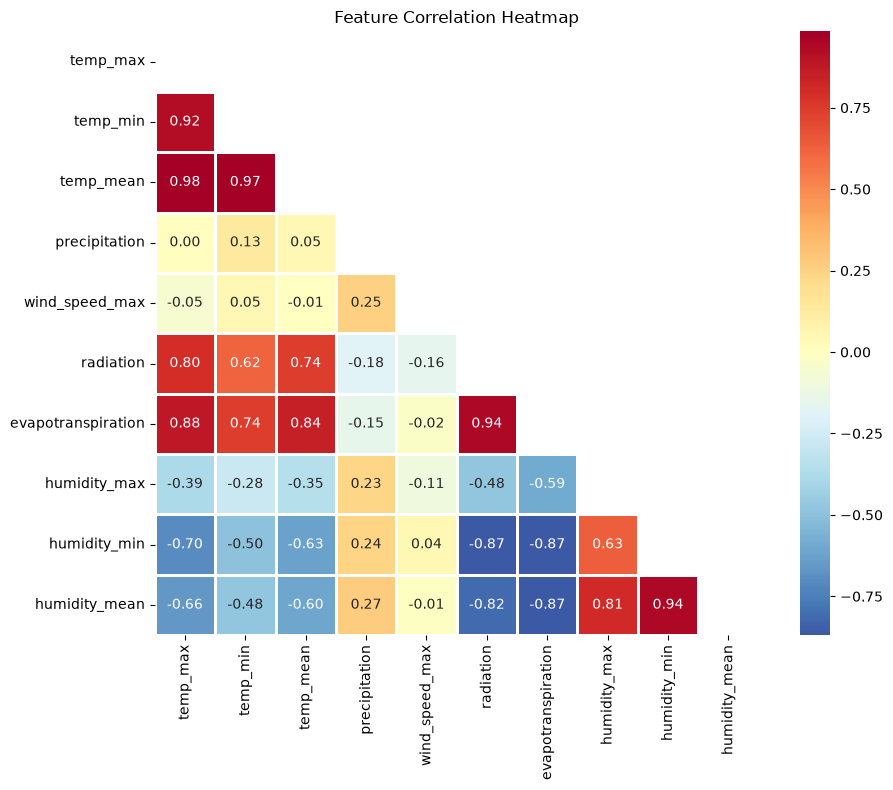

In [6]:
# Visualization 2: Correlation heatmap
fig, ax = plt.subplots(figsize=(10, 8))
correlation = df.corr()
mask = np.triu(np.ones_like(correlation, dtype=bool))
sns.heatmap(correlation, annot=True, fmt='.2f', cmap='RdYlBu_r', mask=mask,
            center=0, square=True, linewidths=1, ax=ax)
ax.set_title('Feature Correlation Heatmap')
plt.tight_layout()
plt.show()

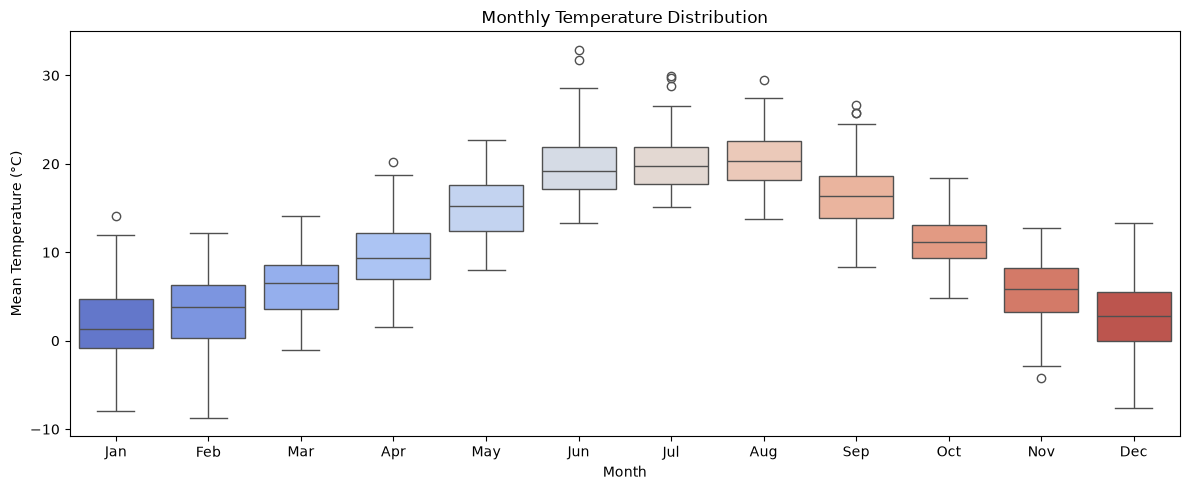

In [7]:
# Visualization 3: Monthly temperature distribution
df_plot = df.copy()
df_plot['month'] = df_plot.index.month
df_plot['month_name'] = df_plot.index.strftime('%b')

fig, ax = plt.subplots(figsize=(12, 5))
month_order = ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun',
               'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec']
sns.boxplot(data=df_plot, x='month_name', y='temp_mean', order=month_order,
            palette='coolwarm', ax=ax)
ax.set_title('Monthly Temperature Distribution')
ax.set_xlabel('Month')
ax.set_ylabel('Mean Temperature (°C)')
plt.tight_layout()
plt.show()

# Stage 4: Data Preprocessing

Steps:
1. Handle missing values (forward fill + backward fill)
2. Normalize all features using MinMaxScaler (fit on the training period only)
3. Split data into training (80%) and testing (20%) sets

**V1.1 methodological correction:** the scaler is fitted only on observations belonging to the training period. The original V1 fitted the scaler on the complete dataset before the train/test split, which allowed test-period information to influence the scaling parameters.


In [8]:
# Handle missing values
df_clean = df.copy()
df_clean = df_clean.ffill().bfill()
print(f"Missing values after cleaning: {df_clean.isnull().sum().sum()}")

# ============================================================
# V1.1 FIX: fit scalers on the training period only
# ============================================================
# The sequence split is defined later using:
#   LOOKBACK = 30
#   split = int(len(X) * 0.8)
# To keep exactly the same 80/20 sequence split as V1, calculate
# the corresponding raw-data endpoint here.

LOOKBACK_FOR_SCALING = 30
N_SEQUENCES = len(df_clean) - LOOKBACK_FOR_SCALING
split = int(N_SEQUENCES * 0.8)
train_end_raw = LOOKBACK_FOR_SCALING + split

train_raw = df_clean.iloc[:train_end_raw].copy()

scaler = MinMaxScaler(feature_range=(0, 1))
scaler.fit(train_raw)
scaled_data = scaler.transform(df_clean)
scaled_df = pd.DataFrame(scaled_data, columns=df_clean.columns, index=df_clean.index)

print(f"Training observations used to fit scaler: {len(train_raw)}")
print(f"Scaler training period: {train_raw.index.min().date()} to {train_raw.index.max().date()}")
print(f"Full transformed data range: [{scaled_data.min():.2f}, {scaled_data.max():.2f}]")
print(f"Features: {list(df_clean.columns)}")

# Separate scaler for the target variable, also fitted on training data only.
target_col_idx = list(df_clean.columns).index('temp_mean')
target_scaler = MinMaxScaler(feature_range=(0, 1))
target_scaler.fit(train_raw[['temp_mean']])

scaled_df.head()


Missing values after cleaning: 0
Training observations used to fit scaler: 1466
Scaler training period: 2021-09-28 to 2025-10-02
Full transformed data range: [-0.08, 1.17]
Features: ['temp_max', 'temp_min', 'temp_mean', 'precipitation', 'wind_speed_max', 'radiation', 'evapotranspiration', 'humidity_max', 'humidity_min', 'humidity_mean']


,temp_max,temp_min,temp_mean,precipitation,wind_speed_max,radiation,evapotranspiration,humidity_max,humidity_min,humidity_mean
date,,,,,,,,,,
2021-09-28,0.509569,0.732759,0.619048,0.024831,0.254989,0.224203,0.149367,0.882353,0.647059,0.802817
2021-09-29,0.490431,0.712644,0.574074,0.209932,0.303769,0.128214,0.093671,1.000000,0.752941,0.873239
2021-09-30,0.447368,0.649425,0.513228,0.020316,0.445676,0.317107,0.240506,0.666667,0.541176,0.605634
2021-10-01,0.519139,0.603448,0.531746,0.000000,0.308204,0.403154,0.311392,0.568627,0.388235,0.507042
2021-10-02,0.564593,0.646552,0.582011,0.000000,0.337029,0.375728,0.278481,0.705882,0.505882,0.619718


# Stage 5: Feature Engineering

**Key decisions:**
- **Lookback window:** 30 days — the model uses the past 30 days of all features to predict the next day's mean temperature
- **Target variable:** `temp_mean` (daily mean temperature)
- **Temporal features:** Day of year and month are encoded as cyclical (sin/cos) features to capture seasonality

In [9]:
# Add cyclical temporal features
df_featured = scaled_df.copy()
day_of_year = df_featured.index.dayofyear
df_featured['day_sin'] = np.sin(2 * np.pi * day_of_year / 365.25)
df_featured['day_cos'] = np.cos(2 * np.pi * day_of_year / 365.25)
month = df_featured.index.month
df_featured['month_sin'] = np.sin(2 * np.pi * month / 12)
df_featured['month_cos'] = np.cos(2 * np.pi * month / 12)

print(f"Features after engineering: {list(df_featured.columns)}")
print(f"Total features: {len(df_featured.columns)}")

# Create sequences for LSTM
LOOKBACK = 30  # days to look back
TARGET_COL = 'temp_mean'

def create_sequences(data, target_col, lookback):
    X, y = [], []
    target_idx = list(data.columns).index(target_col)
    values = data.values

    for i in range(lookback, len(values)):
        X.append(values[i - lookback:i])
        y.append(values[i, target_idx])

    return np.array(X), np.array(y)

X, y = create_sequences(df_featured, TARGET_COL, LOOKBACK)

# Train/test split (80/20, no shuffle — time series!)
# `split` was already calculated above to match this sequence split.
X_train, X_test = X[:split], X[split:]
y_train, y_test = y[:split], y[split:]

print(f"\nSequence shape: X={X.shape}, y={y.shape}")
print(f"Training set: X_train={X_train.shape}, y_train={y_train.shape}")
print(f"Test set:     X_test={X_test.shape}, y_test={y_test.shape}")
print(f"\nEach sample: {LOOKBACK} days × {X.shape[2]} features → 1 temperature prediction")

Features after engineering: ['temp_max', 'temp_min', 'temp_mean', 'precipitation', 'wind_speed_max', 'radiation', 'evapotranspiration', 'humidity_max', 'humidity_min', 'humidity_mean', 'day_sin', 'day_cos', 'month_sin', 'month_cos']
Total features: 14

Sequence shape: X=(1796, 30, 14), y=(1796,)
Training set: X_train=(1436, 30, 14), y_train=(1436,)
Test set:     X_test=(360, 30, 14), y_test=(360,)

Each sample: 30 days × 14 features → 1 temperature prediction


# Stage 5b: Hyperparameter Tuning

We use **Keras Tuner (Hyperband)** to systematically search for optimal hyperparameters for both the LSTM and Transformer models.

**Tuned hyperparameters (LSTM):**
- Number of LSTM units (Layer 1 & 2)
- Dropout rate
- Learning rate
- Dense layer units

**Tuned hyperparameters (Transformer):**
- Number of attention heads
- Feed-forward dimension
- Number of encoder blocks
- Dropout rate
- Learning rate

This replaces manual guessing with a principled search, significantly improving model accuracy.

In [10]:
import keras_tuner as kt
from tensorflow.keras.layers import (
    Input, Dense, Dropout, LayerNormalization,
    MultiHeadAttention, GlobalAveragePooling1D, Add
)
from tensorflow.keras.models import Model

# Define Transformer helpers here so both tuner and final model can use them

def positional_encoding(length, depth):
    """Generate sinusoidal positional encoding."""
    positions = np.arange(length)[:, np.newaxis]
    dims = np.arange(depth)[np.newaxis, :]
    angles = positions / np.power(10000, (2 * (dims // 2)) / depth)
    angles[:, 0::2] = np.sin(angles[:, 0::2])
    angles[:, 1::2] = np.cos(angles[:, 1::2])
    return tf.cast(angles[np.newaxis, :, :], dtype=tf.float32)

def transformer_encoder_block(inputs, num_heads, ff_dim, dropout_rate=0.1):
    """Single Transformer encoder block."""
    attn_output = MultiHeadAttention(num_heads=num_heads, key_dim=inputs.shape[-1])(inputs, inputs)
    attn_output = Dropout(dropout_rate)(attn_output)
    out1 = LayerNormalization(epsilon=1e-6)(Add()([inputs, attn_output]))

    ff_output = Dense(ff_dim, activation='relu')(out1)
    ff_output = Dense(inputs.shape[-1])(ff_output)
    ff_output = Dropout(dropout_rate)(ff_output)
    out2 = LayerNormalization(epsilon=1e-6)(Add()([out1, ff_output]))
    return out2

# ========== LSTM Hyperparameter Tuning ==========

def build_lstm_hp(hp):
    lstm1_units = hp.Int('lstm1_units', min_value=64, max_value=256, step=64)
    lstm2_units = hp.Int('lstm2_units', min_value=32, max_value=128, step=32)
    dropout_rate = hp.Float('dropout', min_value=0.1, max_value=0.4, step=0.1)
    dense_units = hp.Int('dense_units', min_value=16, max_value=64, step=16)
    learning_rate = hp.Choice('learning_rate', values=[1e-2, 1e-3, 5e-4, 1e-4])

    m = Sequential([
        Bidirectional(LSTM(lstm1_units, return_sequences=True,
                          input_shape=(LOOKBACK, X_train.shape[2]))),
        Dropout(dropout_rate),
        LSTM(lstm2_units, return_sequences=False),
        Dropout(dropout_rate),
        Dense(dense_units, activation='relu'),
        Dense(1)
    ])
    m.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=learning_rate),
              loss='mse', metrics=['mae'])
    return m

lstm_tuner = kt.Hyperband(
    build_lstm_hp,
    objective='val_loss',
    max_epochs=40,
    factor=3,
    directory='tuner_results',
    project_name='lstm_weather',
    overwrite=True
)

print("=" * 60)
print("  LSTM HYPERPARAMETER SEARCH (Hyperband)")
print("=" * 60)

lstm_tuner.search(
    X_train, y_train,
    validation_split=0.15,
    epochs=40,
    batch_size=32,
    callbacks=[EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True)],
    verbose=0
)

best_lstm_hp = lstm_tuner.get_best_hyperparameters(1)[0]
print("\nBest LSTM Hyperparameters:")
print(f"  LSTM Layer 1 units: {best_lstm_hp.get('lstm1_units')}")
print(f"  LSTM Layer 2 units: {best_lstm_hp.get('lstm2_units')}")
print(f"  Dropout rate:       {best_lstm_hp.get('dropout')}")
print(f"  Dense units:        {best_lstm_hp.get('dense_units')}")
print(f"  Learning rate:      {best_lstm_hp.get('learning_rate')}")

# ========== Transformer Hyperparameter Tuning ==========

def build_transformer_hp(hp):
    num_heads = hp.Choice('num_heads', values=[2, 4, 8])
    ff_dim = hp.Int('ff_dim', min_value=64, max_value=256, step=64)
    num_blocks = hp.Int('num_blocks', min_value=1, max_value=3, step=1)
    dropout_rate = hp.Float('dropout', min_value=0.05, max_value=0.3, step=0.05)
    learning_rate = hp.Choice('learning_rate', values=[1e-2, 1e-3, 5e-4, 1e-4])
    dense_units = hp.Int('dense_units', min_value=32, max_value=128, step=32)

    n_feat = X_train.shape[2]
    inputs = Input(shape=(LOOKBACK, n_feat))
    proj_dim = ((n_feat // num_heads) + 1) * num_heads
    x = Dense(proj_dim)(inputs)
    pos_enc = positional_encoding(LOOKBACK, proj_dim)
    x = x + pos_enc
    x = Dropout(dropout_rate)(x)

    for _ in range(num_blocks):
        x = transformer_encoder_block(x, num_heads=num_heads, ff_dim=ff_dim,
                                       dropout_rate=dropout_rate)

    x = GlobalAveragePooling1D()(x)
    x = Dense(dense_units, activation='relu')(x)
    x = Dropout(dropout_rate)(x)
    x = Dense(dense_units // 2, activation='relu')(x)
    x = Dense(1)(x)

    m = Model(inputs=inputs, outputs=x)
    m.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=learning_rate),
              loss='mse', metrics=['mae'])
    return m

transformer_tuner = kt.Hyperband(
    build_transformer_hp,
    objective='val_loss',
    max_epochs=40,
    factor=3,
    directory='tuner_results',
    project_name='transformer_weather',
    overwrite=True
)

print("\n" + "=" * 60)
print("  TRANSFORMER HYPERPARAMETER SEARCH (Hyperband)")
print("=" * 60)

transformer_tuner.search(
    X_train, y_train,
    validation_split=0.15,
    epochs=40,
    batch_size=32,
    callbacks=[EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True)],
    verbose=0
)

best_trans_hp = transformer_tuner.get_best_hyperparameters(1)[0]
print("\nBest Transformer Hyperparameters:")
print(f"  Attention heads:  {best_trans_hp.get('num_heads')}")
print(f"  FF dimension:     {best_trans_hp.get('ff_dim')}")
print(f"  Encoder blocks:   {best_trans_hp.get('num_blocks')}")
print(f"  Dropout rate:     {best_trans_hp.get('dropout')}")
print(f"  Dense units:      {best_trans_hp.get('dense_units')}")
print(f"  Learning rate:    {best_trans_hp.get('learning_rate')}")

  LSTM HYPERPARAMETER SEARCH (Hyperband)

Best LSTM Hyperparameters:
  LSTM Layer 1 units: 192
  LSTM Layer 2 units: 96
  Dropout rate:       0.1
  Dense units:        32
  Learning rate:      0.01

  TRANSFORMER HYPERPARAMETER SEARCH (Hyperband)

Best Transformer Hyperparameters:
  Attention heads:  2
  FF dimension:     128
  Encoder blocks:   1
  Dropout rate:     0.05
  Dense units:      96
  Learning rate:    0.01


# Stage 6: Model Training

Both models are now built using the **best hyperparameters** found by Keras Tuner (Hyperband search).

**Training strategy:**
- Optimizer: Adam (tuned learning rate)
- Loss: Mean Squared Error (MSE)
- Early stopping with patience=15 to prevent overfitting
- Learning rate reduction on plateau

In [11]:
# Build the LSTM model using tuned hyperparameters
n_features = X_train.shape[2]

model = Sequential([
    Bidirectional(LSTM(best_lstm_hp.get('lstm1_units'), return_sequences=True,
                       input_shape=(LOOKBACK, n_features))),
    Dropout(best_lstm_hp.get('dropout')),
    LSTM(best_lstm_hp.get('lstm2_units'), return_sequences=False),
    Dropout(best_lstm_hp.get('dropout')),
    Dense(best_lstm_hp.get('dense_units'), activation='relu'),
    Dense(1)
])

model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=best_lstm_hp.get('learning_rate')),
              loss='mse',
              metrics=['mae'])

print(f"LSTM model built with tuned hyperparameters:")
print(f"  Units: {best_lstm_hp.get('lstm1_units')}/{best_lstm_hp.get('lstm2_units')}, "
      f"Dropout: {best_lstm_hp.get('dropout')}, "
      f"Dense: {best_lstm_hp.get('dense_units')}, "
      f"LR: {best_lstm_hp.get('learning_rate')}")
model.summary()

LSTM model built with tuned hyperparameters:
  Units: 192/96, Dropout: 0.1, Dense: 32, LR: 0.01


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ bidirectional (Bidirectional)   │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_8 (Dropout)             │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_9 (Dropout)             │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_9 (Dense)                 │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

In [12]:
# Train the model
callbacks = [
    EarlyStopping(monitor='val_loss', patience=15, restore_best_weights=True, verbose=1),
    ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=5, min_lr=1e-6, verbose=1)
]

history = model.fit(
    X_train, y_train,
    validation_split=0.15,
    epochs=100,
    batch_size=32,
    callbacks=callbacks,
    verbose=1
)

print(f"\nTraining completed!")
print(f"Best validation loss: {min(history.history['val_loss']):.6f}")

Epoch 1/100
39/39 ━━━━━━━━━━━━━━━━━━━━ 4s 43ms/step - loss: 0.0725 - mae: 0.1574 - val_loss: 0.0059 - val_mae: 0.0623 - learning_rate: 0.0100
Epoch 2/100
39/39 ━━━━━━━━━━━━━━━━━━━━ 1s 38ms/step - loss: 0.0093 - mae: 0.0768 - val_loss: 0.0060 - val_mae: 0.0629 - learning_rate: 0.0100
Epoch 3/100
39/39 ━━━━━━━━━━━━━━━━━━━━ 2s 45ms/step - loss: 0.0078 - mae: 0.0712 - val_loss: 0.0065 - val_mae: 0.0651 - learning_rate: 0.0100
Epoch 4/100
39/39 ━━━━━━━━━━━━━━━━━━━━ 2s 49ms/step - loss: 0.0076 - mae: 0.0696 - val_loss: 0.0085 - val_mae: 0.0758 - learning_rate: 0.0100
Epoch 5/100
39/39 ━━━━━━━━━━━━━━━━━━━━ 2s 50ms/step - loss: 0.0073 - mae: 0.0681 - val_loss: 0.0044 - val_mae: 0.0537 - learning_rate: 0.0100
Epoch 6/100
39/39 ━━━━━━━━━━━━━━━━━━━━ 2s 50ms/step - loss: 0.0058 - mae: 0.0609 - val_loss: 0.0044 - val_mae: 0.0526 - learning_rate: 0.0100
Epoch 7/100
39/39 ━━━━━━━━━━━━━━━━━━━━ 2s 49ms/step - loss: 0.0058 - mae: 0.0609 - val_loss: 0.0066 - val_mae: 0.0662 - learning_rate: 0.0100
Epoch 

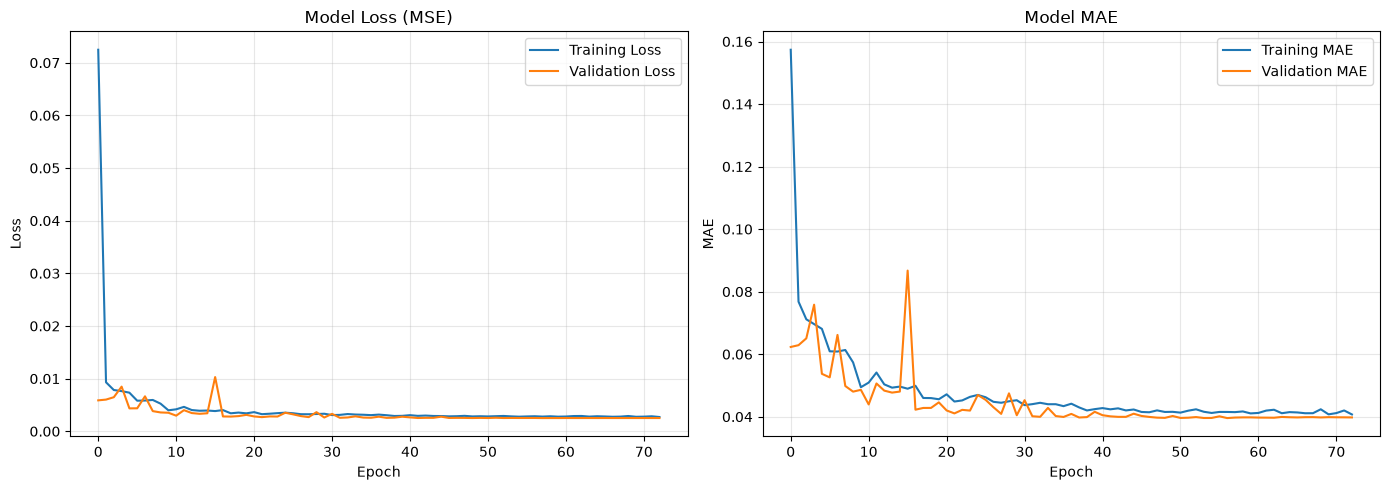

In [13]:
# Training history plots
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(history.history['loss'], label='Training Loss')
axes[0].plot(history.history['val_loss'], label='Validation Loss')
axes[0].set_title('Model Loss (MSE)')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Loss')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

axes[1].plot(history.history['mae'], label='Training MAE')
axes[1].plot(history.history['val_mae'], label='Validation MAE')
axes[1].set_title('Model MAE')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('MAE')
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# Stage 7: Model Evaluation

We evaluate the model on the held-out test set using:
- **MAE** (Mean Absolute Error) — average prediction error in °C
- **RMSE** (Root Mean Squared Error) — penalizes large errors
- **R² Score** — proportion of variance explained
- **MAPE** (Mean Absolute Percentage Error) — retained for continuity with V1

**Metric note:** MAPE is problematic for temperature in °C because the target can be zero or close to zero (and can be negative). Therefore, MAE, RMSE and R² are treated as the principal evaluation metrics. MAPE is reported only as a supplementary V1-compatible metric and should not be used to select a model.


In [14]:
# Make predictions
y_pred_scaled = model.predict(X_test).flatten()

# Inverse transform to get actual temperatures
y_test_actual = target_scaler.inverse_transform(y_test.reshape(-1, 1)).flatten()
y_pred_actual = target_scaler.inverse_transform(y_pred_scaled.reshape(-1, 1)).flatten()

# Calculate metrics
mae = mean_absolute_error(y_test_actual, y_pred_actual)
rmse = np.sqrt(mean_squared_error(y_test_actual, y_pred_actual))
r2 = r2_score(y_test_actual, y_pred_actual)

# Retained for continuity with V1, but not used for model selection.
mape = np.mean(np.abs((y_test_actual - y_pred_actual) / (y_test_actual + 1e-8))) * 100

# Symmetric MAPE is less sensitive to the sign/scale problem of Celsius temperature.
smape = np.mean(
    2 * np.abs(y_test_actual - y_pred_actual) /
    (np.abs(y_test_actual) + np.abs(y_pred_actual) + 1e-8)
) * 100

print("=" * 50)
print("MODEL EVALUATION RESULTS")
print("=" * 50)
print(f"  MAE:  {mae:.2f} °C")
print(f"  RMSE: {rmse:.2f} °C")
print(f"  R²:   {r2:.4f}")
print(f"  MAPE: {mape:.2f}%  [supplementary; not used for selection]")
print(f"  sMAPE: {smape:.2f}%")
print("=" * 50)

12/12 ━━━━━━━━━━━━━━━━━━━━ 1s 32ms/step
MODEL EVALUATION RESULTS
  MAE:  1.55 °C
  RMSE: 2.01 °C
  R²:   0.9438
  MAPE: 41826187.84%  [supplementary; not used for selection]
  sMAPE: 30.12%


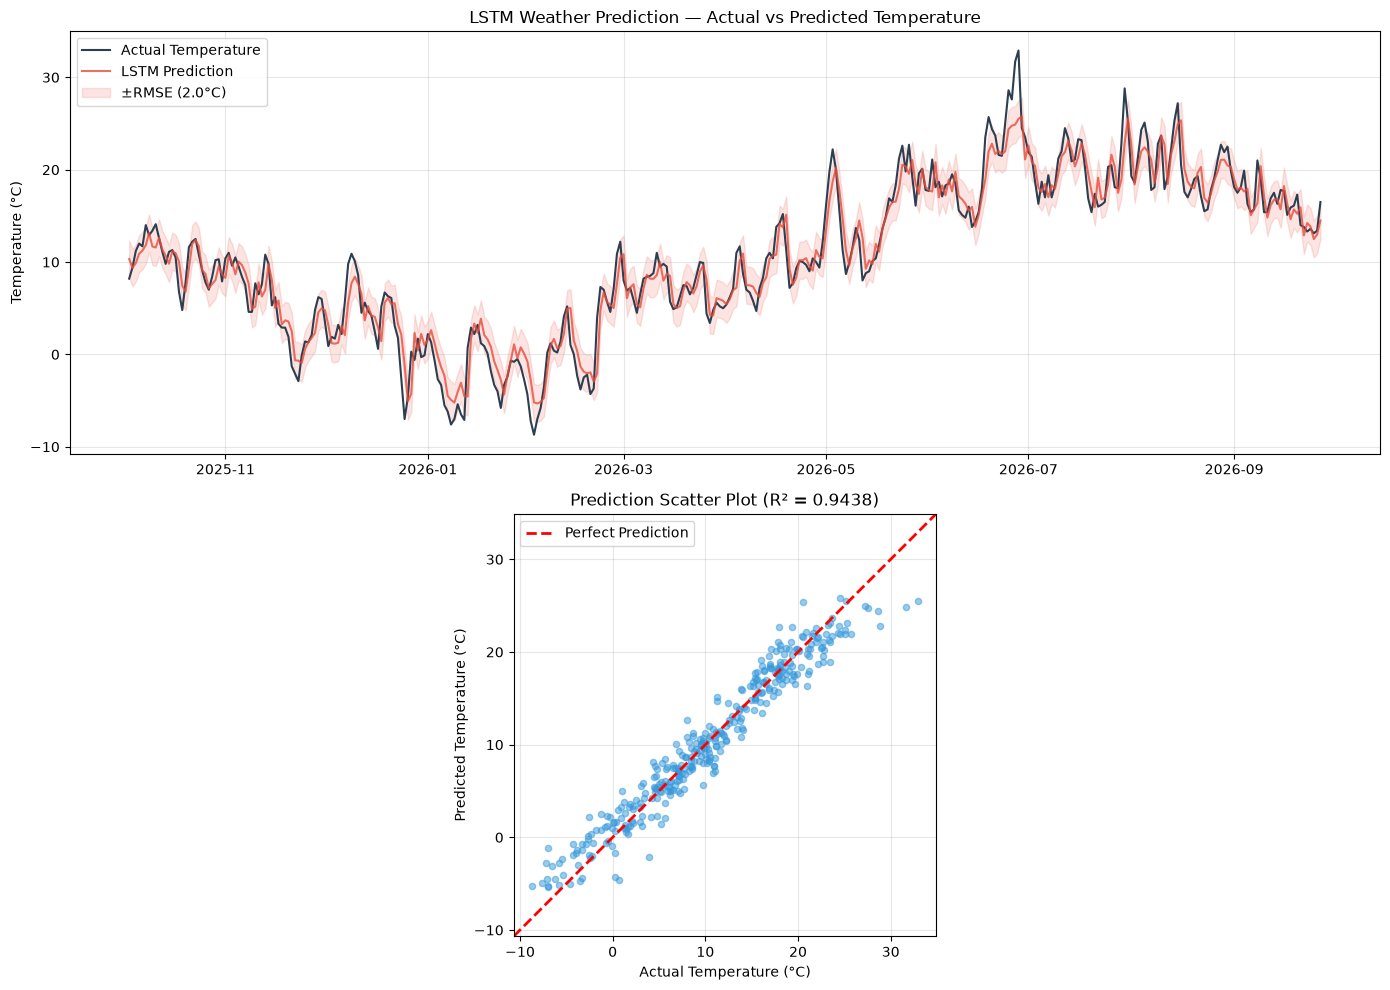

In [15]:
# Visualization: Actual vs Predicted temperatures
test_dates = df_clean.index[split + LOOKBACK:]

fig, axes = plt.subplots(2, 1, figsize=(14, 10))

# Full comparison
axes[0].plot(test_dates, y_test_actual, label='Actual Temperature', color='#2c3e50', linewidth=1.5)
axes[0].plot(test_dates, y_pred_actual, label='LSTM Prediction', color='#e74c3c', linewidth=1.5, alpha=0.8)
axes[0].fill_between(test_dates, y_pred_actual - rmse, y_pred_actual + rmse,
                     alpha=0.15, color='#e74c3c', label=f'±RMSE ({rmse:.1f}°C)')
axes[0].set_title('LSTM Weather Prediction — Actual vs Predicted Temperature')
axes[0].set_ylabel('Temperature (°C)')
axes[0].legend(loc='upper left')
axes[0].grid(True, alpha=0.3)

# Scatter plot
axes[1].scatter(y_test_actual, y_pred_actual, alpha=0.5, s=20, color='#3498db')
min_val = min(y_test_actual.min(), y_pred_actual.min()) - 2
max_val = max(y_test_actual.max(), y_pred_actual.max()) + 2
axes[1].plot([min_val, max_val], [min_val, max_val], 'r--', linewidth=2, label='Perfect Prediction')
axes[1].set_xlabel('Actual Temperature (°C)')
axes[1].set_ylabel('Predicted Temperature (°C)')
axes[1].set_title(f'Prediction Scatter Plot (R² = {r2:.4f})')
axes[1].legend()
axes[1].grid(True, alpha=0.3)
axes[1].set_aspect('equal')
axes[1].set_xlim(min_val, max_val)
axes[1].set_ylim(min_val, max_val)

plt.tight_layout()
plt.show()

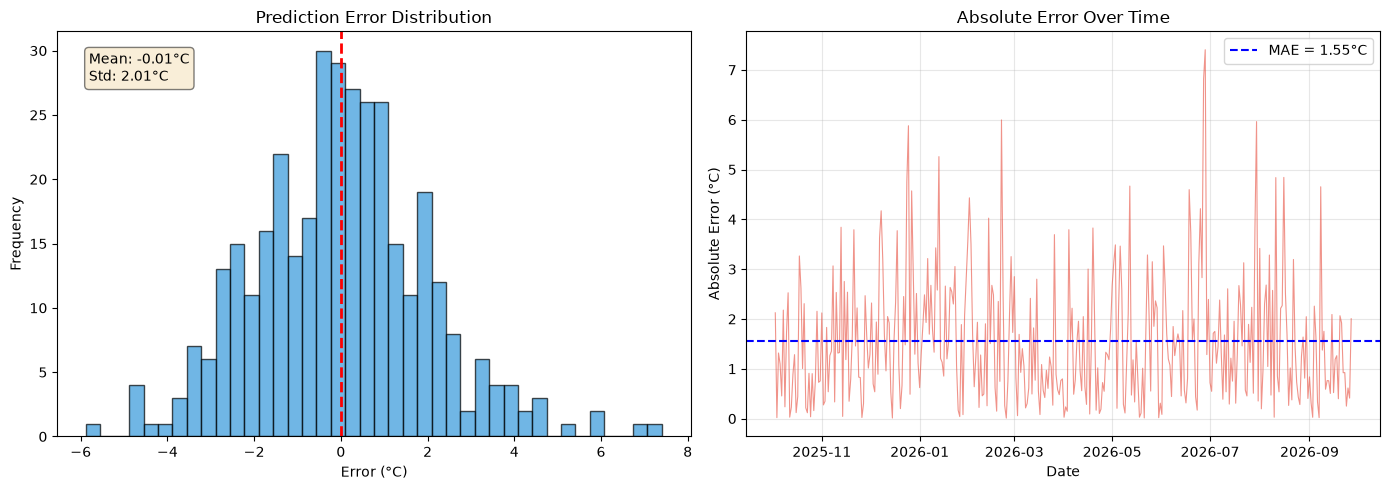

In [16]:
# Error distribution analysis
errors = y_test_actual - y_pred_actual

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].hist(errors, bins=40, edgecolor='black', alpha=0.7, color='#3498db')
axes[0].axvline(x=0, color='red', linestyle='--', linewidth=2)
axes[0].set_title('Prediction Error Distribution')
axes[0].set_xlabel('Error (°C)')
axes[0].set_ylabel('Frequency')
axes[0].text(0.05, 0.95, f'Mean: {errors.mean():.2f}°C\nStd: {errors.std():.2f}°C',
             transform=axes[0].transAxes, va='top',
             bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.5))

axes[1].plot(test_dates, np.abs(errors), alpha=0.6, linewidth=0.8, color='#e74c3c')
axes[1].axhline(y=mae, color='blue', linestyle='--', label=f'MAE = {mae:.2f}°C')
axes[1].set_title('Absolute Error Over Time')
axes[1].set_xlabel('Date')
axes[1].set_ylabel('Absolute Error (°C)')
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# Stage 8: Live Forecast Demo

Using the trained LSTM model to predict the **next 7 days** of temperature by feeding recent weather data from Open-Meteo for **Berlin**.

The V1 forecasting strategy is preserved: the model predicts one day ahead, then feeds the prediction back into the sequence and repeats this process recursively for seven days.


Fetching recent weather data for live forecast...

  7-DAY LSTM TEMPERATURE FORECAST — BERLIN
  Mon 05 Oct 2026:  15.4 °C
  Tue 06 Oct 2026:  15.8 °C
  Wed 07 Oct 2026:  16.1 °C
  Thu 08 Oct 2026:  16.3 °C
  Fri 09 Oct 2026:  16.2 °C
  Sat 10 Oct 2026:  15.9 °C
  Sun 11 Oct 2026:  15.6 °C


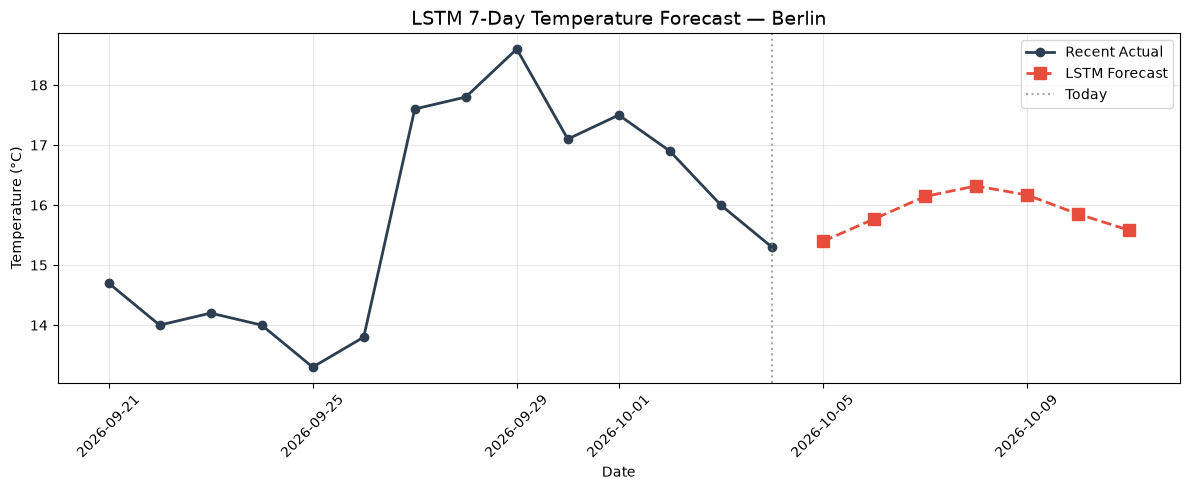

In [17]:
def forecast_next_days(model, scaler, target_scaler, df_featured, n_days=7):
    """Use the model to forecast the next n_days iteratively."""
    last_sequence = df_featured.values[-LOOKBACK:]
    predictions = []

    current_seq = last_sequence.copy()
    for day in range(n_days):
        input_seq = current_seq.reshape(1, LOOKBACK, -1)
        pred_scaled = model.predict(input_seq, verbose=0)[0, 0]
        pred_temp = target_scaler.inverse_transform([[pred_scaled]])[0, 0]
        predictions.append(pred_temp)

        # Shift sequence forward: drop first day, append predicted day
        new_row = current_seq[-1].copy()
        new_row[list(df_featured.columns).index('temp_mean')] = pred_scaled
        current_seq = np.vstack([current_seq[1:], new_row])

    return predictions

# Fetch the most recent data for live forecasting
recent_url = "https://api.open-meteo.com/v1/forecast"
recent_params = {
    "latitude": 52.52,
    "longitude": 13.405,
    "daily": [
        "temperature_2m_max", "temperature_2m_min", "temperature_2m_mean",
        "precipitation_sum", "windspeed_10m_max",
        "shortwave_radiation_sum", "et0_fao_evapotranspiration",
        "relative_humidity_2m_max", "relative_humidity_2m_min",
        "relative_humidity_2m_mean"
    ],
    "past_days": 30,
    "timezone": "Europe/Berlin"
}

print("Fetching recent weather data for live forecast...")
resp = requests.get(recent_url, params=recent_params)
resp.raise_for_status()
recent_data = resp.json()["daily"]

# Build recent dataframe and process it the same way as training data
df_recent = pd.DataFrame({
    "date": pd.to_datetime(recent_data["time"]),
    "temp_max": recent_data["temperature_2m_max"],
    "temp_min": recent_data["temperature_2m_min"],
    "temp_mean": recent_data["temperature_2m_mean"],
    "precipitation": recent_data["precipitation_sum"],
    "wind_speed_max": recent_data["windspeed_10m_max"],
    "radiation": recent_data["shortwave_radiation_sum"],
    "evapotranspiration": recent_data["et0_fao_evapotranspiration"],
    "humidity_max": recent_data["relative_humidity_2m_max"],
    "humidity_min": recent_data["relative_humidity_2m_min"],
    "humidity_mean": recent_data["relative_humidity_2m_mean"]
})
df_recent.set_index("date", inplace=True)
df_recent = df_recent.ffill().bfill()

# Scale using the same scaler
recent_scaled = pd.DataFrame(
    scaler.transform(df_recent),
    columns=df_recent.columns,
    index=df_recent.index
)

# Add temporal features
day_of_year = recent_scaled.index.dayofyear
recent_scaled['day_sin'] = np.sin(2 * np.pi * day_of_year / 365.25)
recent_scaled['day_cos'] = np.cos(2 * np.pi * day_of_year / 365.25)
month = recent_scaled.index.month
recent_scaled['month_sin'] = np.sin(2 * np.pi * month / 12)
recent_scaled['month_cos'] = np.cos(2 * np.pi * month / 12)

# Generate 7-day LSTM forecast
lstm_forecast = forecast_next_days(model, scaler, target_scaler, recent_scaled, n_days=7)
forecast_dates = [df_recent.index[-1] + timedelta(days=i+1) for i in range(7)]

print("\n" + "=" * 50)
print("  7-DAY LSTM TEMPERATURE FORECAST \u2014 BERLIN")
print("=" * 50)
for date, temp in zip(forecast_dates, lstm_forecast):
    print(f"  {date.strftime('%a %d %b %Y')}:  {temp:.1f} \u00b0C")
print("=" * 50)

# Plot forecast
fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(df_recent.index[-14:], df_recent['temp_mean'].values[-14:],
        'o-', color='#2c3e50', label='Recent Actual', linewidth=2, markersize=6)
ax.plot(forecast_dates, lstm_forecast,
        's--', color='#e74c3c', label='LSTM Forecast', linewidth=2, markersize=8)
ax.axvline(x=df_recent.index[-1], color='gray', linestyle=':', alpha=0.7, label='Today')
ax.set_title('LSTM 7-Day Temperature Forecast \u2014 Berlin', fontsize=14)
ax.set_xlabel('Date')
ax.set_ylabel('Temperature (\u00b0C)')
ax.legend()
ax.grid(True, alpha=0.3)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# Stage 9: Transformer Model (Comparison)

We now build a **Transformer-based model** using multi-head self-attention to compare against the LSTM. The Transformer can attend to all positions in the input sequence simultaneously, potentially capturing long-range dependencies more effectively.

**Architecture:**
- Positional encoding (sinusoidal)
- Transformer encoder blocks (multi-head attention + feed-forward)
- Global average pooling → Dense output

**Same V1 data, same split, same preprocessing strategy, same one-step target** — only the model architecture changes.


In [18]:
# Build the Transformer model using tuned hyperparameters
t_heads = best_trans_hp.get('num_heads')
t_ff = best_trans_hp.get('ff_dim')
t_blocks = best_trans_hp.get('num_blocks')
t_drop = best_trans_hp.get('dropout')
t_dense = best_trans_hp.get('dense_units')
t_lr = best_trans_hp.get('learning_rate')

inputs = Input(shape=(LOOKBACK, n_features))
proj_dim = ((n_features // t_heads) + 1) * t_heads
x = Dense(proj_dim)(inputs)
pos_enc = positional_encoding(LOOKBACK, proj_dim)
x = x + pos_enc
x = Dropout(t_drop)(x)

for _ in range(t_blocks):
    x = transformer_encoder_block(x, num_heads=t_heads, ff_dim=t_ff, dropout_rate=t_drop)

x = GlobalAveragePooling1D()(x)
x = Dense(t_dense, activation='relu')(x)
x = Dropout(t_drop)(x)
x = Dense(t_dense // 2, activation='relu')(x)
x = Dense(1)(x)

transformer_model = Model(inputs=inputs, outputs=x)
transformer_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=t_lr),
    loss='mse',
    metrics=['mae']
)

print(f"Transformer model built with tuned hyperparameters:")
print(f"  Heads: {t_heads}, FF dim: {t_ff}, Blocks: {t_blocks}, "
      f"Dropout: {t_drop}, Dense: {t_dense}, LR: {t_lr}")
transformer_model.summary()

Transformer model built with tuned hyperparameters:
  Heads: 2, FF dim: 128, Blocks: 1, Dropout: 0.05, Dense: 96, LR: 0.01


Model: "functional_2"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_2       │ (None, 30, 14)    │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_10 (Dense)    │ (None, 30, 16)    │        240 │ input_layer_2[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_5 (Add)         │ (None, 30, 16)    │          0 │ dense_10[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_10          │ (None, 30, 16)    │          0 │ add_5[0][0]       │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ multi_head_attenti… │ (None, 30, 16)    │      2,160 │ dropout_10[0][0], │
│ (MultiHeadAttentio… │                   │            │ dropout_10[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_12          │ (None, 30, 16)    │          0 │ multi_head_atten… │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_6 (Add)         │ (None, 30, 16)    │          0 │ dropout_10[0][0], │
│                     │                   │            │ dropout_12[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalizatio… │ (None, 30, 16)    │         32 │ add_6[0][0]       │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_11 (Dense)    │ (None, 30, 128)   │      2,176 │ layer_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_12 (Dense)    │ (None, 30, 16)    │      2,064 │ dense_11[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_13          │ (None, 30, 16)    │          0 │ dense_12[0][0]    │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_7 (Add)         │ (None, 30, 16)    │          0 │ layer_normalizat… │
│                     │                   │            │ dropout_13[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalizatio… │ (None, 30, 16)    │         32 │ add_7[0][0]       │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_average_poo… │ (None, 16)        │          0 │ layer_normalizat… │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_13 (Dense)    │ (None, 96)        │      1,632 │ global_average_p… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_14          │ (None, 96)        │          0 │ dense_13[0][0]    │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_14 (Dense)    │ (None, 48)        │      4,656 │ dropout_14[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_15 (Dense)    │ (None, 1)         │         49 │ dense_14[0][0]    │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 13,041 (50.94 KB)

 Trainable params: 13,041 (50.94 KB)

 Non-trainable params: 0 (0.00 B)

In [19]:
# Train the Transformer model
transformer_callbacks = [
    EarlyStopping(monitor='val_loss', patience=15, restore_best_weights=True, verbose=1),
    ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=5, min_lr=1e-6, verbose=1)
]

transformer_history = transformer_model.fit(
    X_train, y_train,
    validation_split=0.15,
    epochs=100,
    batch_size=32,
    callbacks=transformer_callbacks,
    verbose=1
)

print(f"\nTransformer training completed!")
print(f"Best validation loss: {min(transformer_history.history['val_loss']):.6f}")

Epoch 1/100
39/39 ━━━━━━━━━━━━━━━━━━━━ 3s 11ms/step - loss: 0.0417 - mae: 0.1233 - val_loss: 0.0118 - val_mae: 0.0849 - learning_rate: 0.0100
Epoch 2/100
39/39 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.0105 - mae: 0.0830 - val_loss: 0.0069 - val_mae: 0.0651 - learning_rate: 0.0100
Epoch 3/100
39/39 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.0104 - mae: 0.0818 - val_loss: 0.0097 - val_mae: 0.0821 - learning_rate: 0.0100
Epoch 4/100
39/39 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.0089 - mae: 0.0765 - val_loss: 0.0156 - val_mae: 0.1020 - learning_rate: 0.0100
Epoch 5/100
39/39 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.0099 - mae: 0.0796 - val_loss: 0.0055 - val_mae: 0.0589 - learning_rate: 0.0100
Epoch 6/100
39/39 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.0078 - mae: 0.0706 - val_loss: 0.0051 - val_mae: 0.0568 - learning_rate: 0.0100
Epoch 7/100
39/39 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.0066 - mae: 0.0642 - val_loss: 0.0065 - val_mae: 0.0662 - learning_rate: 0.0100
Epoch 8/100


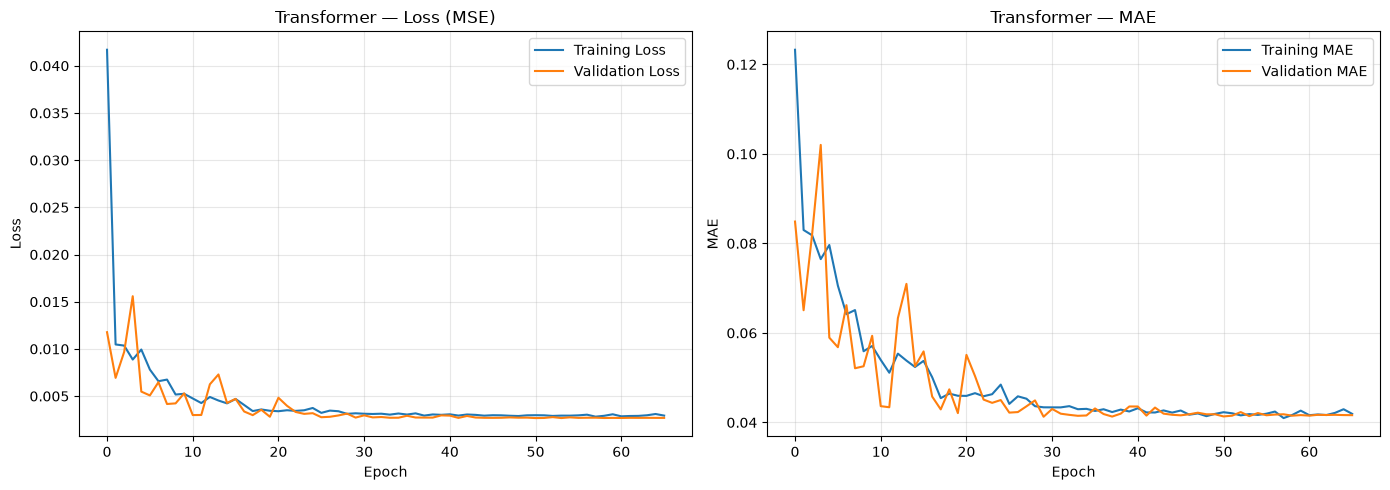

In [20]:
# Transformer training history
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(transformer_history.history['loss'], label='Training Loss')
axes[0].plot(transformer_history.history['val_loss'], label='Validation Loss')
axes[0].set_title('Transformer — Loss (MSE)')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Loss')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

axes[1].plot(transformer_history.history['mae'], label='Training MAE')
axes[1].plot(transformer_history.history['val_mae'], label='Validation MAE')
axes[1].set_title('Transformer — MAE')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('MAE')
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# Stage 10: Transformer Model Evaluation

In [21]:
# Transformer predictions
y_pred_transformer_scaled = transformer_model.predict(X_test).flatten()
y_pred_transformer = target_scaler.inverse_transform(y_pred_transformer_scaled.reshape(-1, 1)).flatten()

# Calculate Transformer metrics
trans_mae = mean_absolute_error(y_test_actual, y_pred_transformer)
trans_rmse = np.sqrt(mean_squared_error(y_test_actual, y_pred_transformer))
trans_r2 = r2_score(y_test_actual, y_pred_transformer)
trans_mape = np.mean(np.abs((y_test_actual - y_pred_transformer) / (y_test_actual + 1e-8))) * 100
trans_smape = np.mean(
    2 * np.abs(y_test_actual - y_pred_transformer) /
    (np.abs(y_test_actual) + np.abs(y_pred_transformer) + 1e-8)
) * 100

print("=" * 50)
print("TRANSFORMER EVALUATION RESULTS")
print("=" * 50)
print(f"  MAE:  {trans_mae:.2f} °C")
print(f"  RMSE: {trans_rmse:.2f} °C")
print(f"  R²:   {trans_r2:.4f}")
print(f"  MAPE: {trans_mape:.2f}%  [supplementary; not used for selection]")
print(f"  sMAPE: {trans_smape:.2f}%")
print("=" * 50)

12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step
TRANSFORMER EVALUATION RESULTS
  MAE:  1.57 °C
  RMSE: 2.06 °C
  R²:   0.9412
  MAPE: 54022729.51%  [supplementary; not used for selection]
  sMAPE: 30.65%


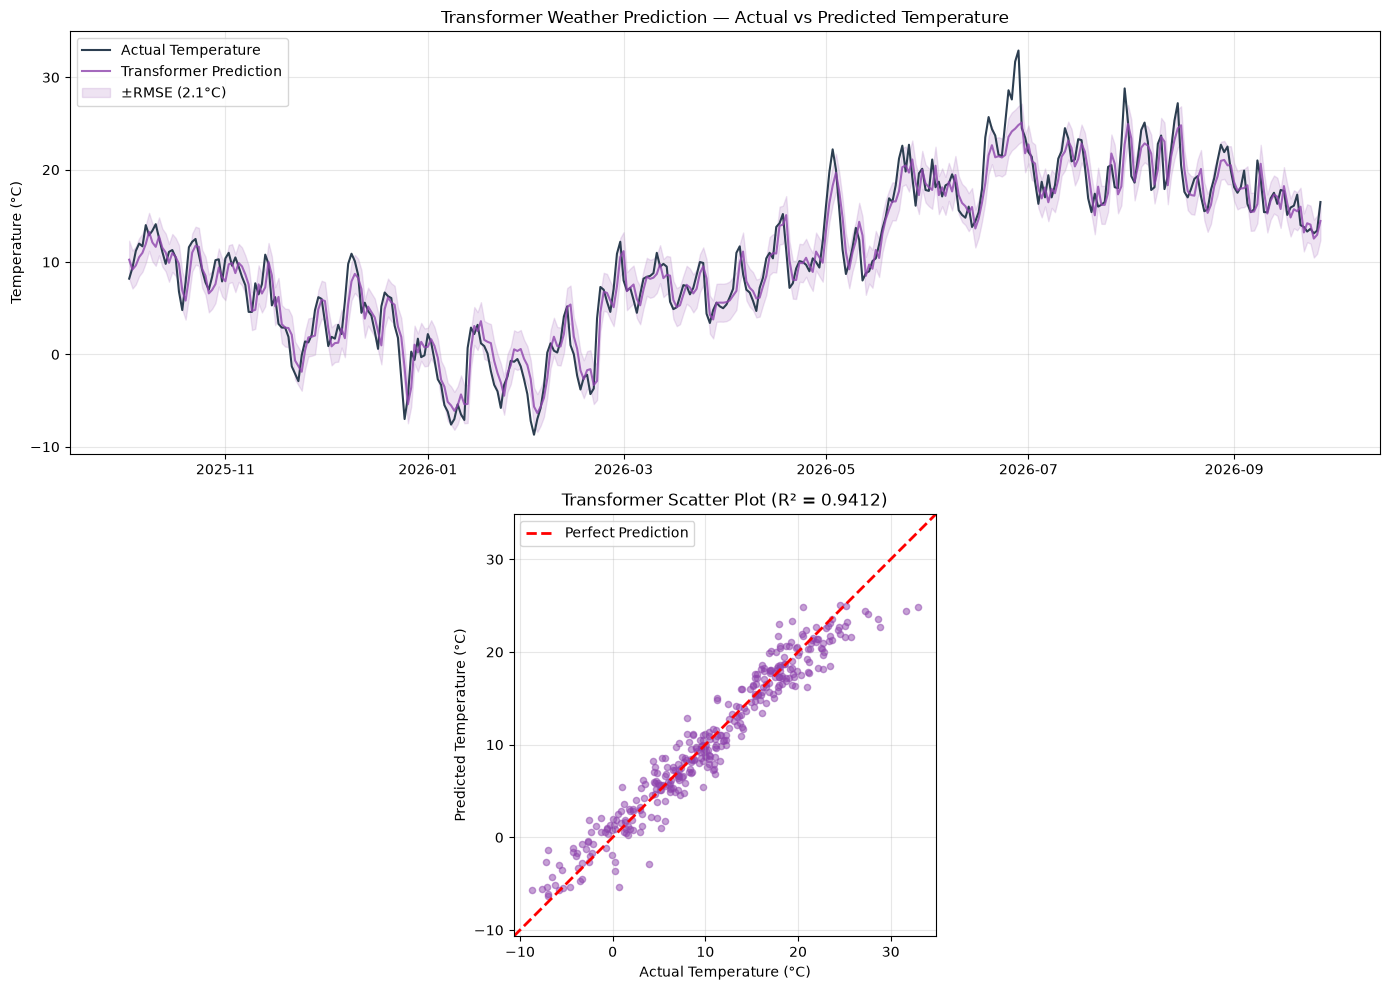

In [22]:
# Transformer: Actual vs Predicted
fig, axes = plt.subplots(2, 1, figsize=(14, 10))

axes[0].plot(test_dates, y_test_actual, label='Actual Temperature', color='#2c3e50', linewidth=1.5)
axes[0].plot(test_dates, y_pred_transformer, label='Transformer Prediction', color='#8e44ad', linewidth=1.5, alpha=0.8)
axes[0].fill_between(test_dates, y_pred_transformer - trans_rmse, y_pred_transformer + trans_rmse,
                     alpha=0.15, color='#8e44ad', label=f'±RMSE ({trans_rmse:.1f}°C)')
axes[0].set_title('Transformer Weather Prediction — Actual vs Predicted Temperature')
axes[0].set_ylabel('Temperature (°C)')
axes[0].legend(loc='upper left')
axes[0].grid(True, alpha=0.3)

axes[1].scatter(y_test_actual, y_pred_transformer, alpha=0.5, s=20, color='#8e44ad')
min_val = min(y_test_actual.min(), y_pred_transformer.min()) - 2
max_val = max(y_test_actual.max(), y_pred_transformer.max()) + 2
axes[1].plot([min_val, max_val], [min_val, max_val], 'r--', linewidth=2, label='Perfect Prediction')
axes[1].set_xlabel('Actual Temperature (°C)')
axes[1].set_ylabel('Predicted Temperature (°C)')
axes[1].set_title(f'Transformer Scatter Plot (R² = {trans_r2:.4f})')
axes[1].legend()
axes[1].grid(True, alpha=0.3)
axes[1].set_aspect('equal')
axes[1].set_xlim(min_val, max_val)
axes[1].set_ylim(min_val, max_val)

plt.tight_layout()
plt.show()

---

# Stage 11: Prophet Model (Statistical Baseline) with Hyperparameter Tuning

**Facebook Prophet** is an additive regression model that decomposes time series into:
- **Trend** — long-term direction
- **Seasonality** — yearly, weekly, daily patterns (automatically detected)
- **Holiday effects** — (not used here)

We perform a **random search** (instead of exhaustive grid search) over Prophet's key hyperparameters — this samples a fixed number of random combinations from the search space, giving good coverage at a fraction of the compute cost:
- `changepoint_prior_scale` — flexibility of the trend (higher = more flexible)
- `seasonality_prior_scale` — strength of seasonality component
- `seasonality_mode` — additive vs multiplicative seasonality
- `changepoint_range` — proportion of history used for trend changepoints

We also add humidity, radiation, wind speed, and precipitation as **extra regressors**.

In [23]:
import logging
import random
from prophet import Prophet

# Silence Prophet/cmdstanpy's verbose fit logging
logging.getLogger('prophet').setLevel(logging.WARNING)
logging.getLogger('cmdstanpy').setLevel(logging.WARNING)

# Prophet requires a DataFrame with 'ds' (date) and 'y' (target) columns
df_prophet = df_clean.reset_index()
df_prophet = df_prophet.rename(columns={'date': 'ds', 'temp_mean': 'y'})

# Use the same train/test split dates as the deep learning models
split_date = df_clean.index[split + LOOKBACK]
df_prophet_train = df_prophet[df_prophet['ds'] < split_date].copy()
df_prophet_test = df_prophet[df_prophet['ds'] >= split_date].copy()

print(f"Prophet train: {len(df_prophet_train)} days")
print(f"Prophet test:  {len(df_prophet_test)} days")
print(f"Split date:    {split_date.date()}")

# ============================================================
# V1.1 FIX: tune Prophet on a validation subset of the training
# period, then refit the selected configuration on all training data.
# The final test period is NOT used for hyperparameter selection.
# ============================================================

prophet_val_size = int(len(df_prophet_train) * 0.15)
prophet_inner_train = df_prophet_train.iloc[:-prophet_val_size].copy()
prophet_val = df_prophet_train.iloc[-prophet_val_size:].copy()

print(f"Prophet inner-train: {len(prophet_inner_train)} days")
print(f"Prophet validation:  {len(prophet_val)} days")
print(f"Validation period:  {prophet_val['ds'].min().date()} to {prophet_val['ds'].max().date()}")

# ========== Prophet Hyperparameter Tuning (Random Search) ==========

param_grid = {
    'changepoint_prior_scale': [0.001, 0.01, 0.05, 0.1, 0.5],
    'seasonality_prior_scale': [0.1, 1.0, 5.0, 10.0],
    'seasonality_mode': ['additive', 'multiplicative'],
    'changepoint_range': [0.8, 0.9]
}
regressors = ['humidity_mean', 'radiation', 'wind_speed_max', 'precipitation']

# Full grid would be 5*4*2*2 = 80 combinations.
# Random search samples a fixed budget instead, e.g. 20 trials (~25% of the grid).
N_TRIALS = 20
random.seed(42)

keys = list(param_grid.keys())
sampled_combos = set()
while len(sampled_combos) < N_TRIALS:
    combo = tuple(random.choice(param_grid[k]) for k in keys)
    sampled_combos.add(combo)
sampled_combos = list(sampled_combos)

print(f"\n{'=' * 60}")
print(f"  PROPHET HYPERPARAMETER SEARCH (Random Search)")
print(f"  Sampled trials: {N_TRIALS} (full grid would be 80)")
print(f"{'=' * 60}")

best_mae = float('inf')
best_params = None
results = []

for i, combo in enumerate(sampled_combos):
    params = dict(zip(keys, combo))

    m = Prophet(
        yearly_seasonality=True,
        weekly_seasonality=True,
        daily_seasonality=False,
        **params
    )
    for col in regressors:
        m.add_regressor(col)

    m.fit(prophet_inner_train)

    # Validation uses the chronological holdout inside the training period.
    future = prophet_val[['ds'] + regressors].copy()
    pred = m.predict(future)
    trial_mae = mean_absolute_error(prophet_val['y'].values, pred['yhat'].values)
    results.append((params, trial_mae))

    if trial_mae < best_mae:
        best_mae = trial_mae
        best_params = params

    print(f"  [{i+1:2d}/{N_TRIALS}] Validation MAE={trial_mae:.3f}°C | current best: {best_mae:.3f}°C")

print(f"\n{'=' * 60}")
print("  Best Prophet Hyperparameters:")
print(f"{'=' * 60}")
for k, v in best_params.items():
    print(f"  {k:>28s}: {v}")
print(f"  {'Best validation MAE':>28s}: {best_mae:.3f} °C")
print(f"{'=' * 60}")

# Train final Prophet model with the selected parameters on ALL available
# training observations. The test set remains completely held out.
prophet_model = Prophet(
    yearly_seasonality=True,
    weekly_seasonality=True,
    daily_seasonality=False,
    **best_params
)
for col in regressors:
    prophet_model.add_regressor(col)

prophet_model.fit(df_prophet_train)
print("\nFinal Prophet model trained on the complete training period with validation-selected hyperparameters!")


Importing plotly failed. Interactive plots will not work.
05:31:11 - cmdstanpy - INFO - Chain [1] start processing


Prophet train: 1466 days
Prophet test:  360 days
Split date:    2025-10-03
Prophet inner-train: 1247 days
Prophet validation:  219 days
Validation period:  2025-02-26 to 2025-10-02

  PROPHET HYPERPARAMETER SEARCH (Random Search)
  Sampled trials: 20 (full grid would be 80)


05:31:12 - cmdstanpy - INFO - Chain [1] done processing
05:31:12 - cmdstanpy - INFO - Chain [1] start processing
05:31:12 - cmdstanpy - INFO - Chain [1] done processing


  [ 1/20] Validation MAE=2.532°C | current best: 2.532°C


05:31:12 - cmdstanpy - INFO - Chain [1] start processing
05:31:12 - cmdstanpy - INFO - Chain [1] done processing


  [ 2/20] Validation MAE=2.523°C | current best: 2.523°C


... (22 outputs left out)

05:31:15 - cmdstanpy - INFO - Chain [1] start processing
05:31:15 - cmdstanpy - INFO - Chain [1] done processing
05:31:16 - cmdstanpy - INFO - Chain [1] start processing


  [19/20] Validation MAE=5.111°C | current best: 2.449°C


05:31:16 - cmdstanpy - INFO - Chain [1] done processing
05:31:16 - cmdstanpy - INFO - Chain [1] start processing
05:31:16 - cmdstanpy - INFO - Chain [1] done processing


  [20/20] Validation MAE=3.175°C | current best: 2.449°C

  Best Prophet Hyperparameters:
       changepoint_prior_scale: 0.05
       seasonality_prior_scale: 0.1
              seasonality_mode: additive
             changepoint_range: 0.8
           Best validation MAE: 2.449 °C

Final Prophet model trained on the complete training period with validation-selected hyperparameters!


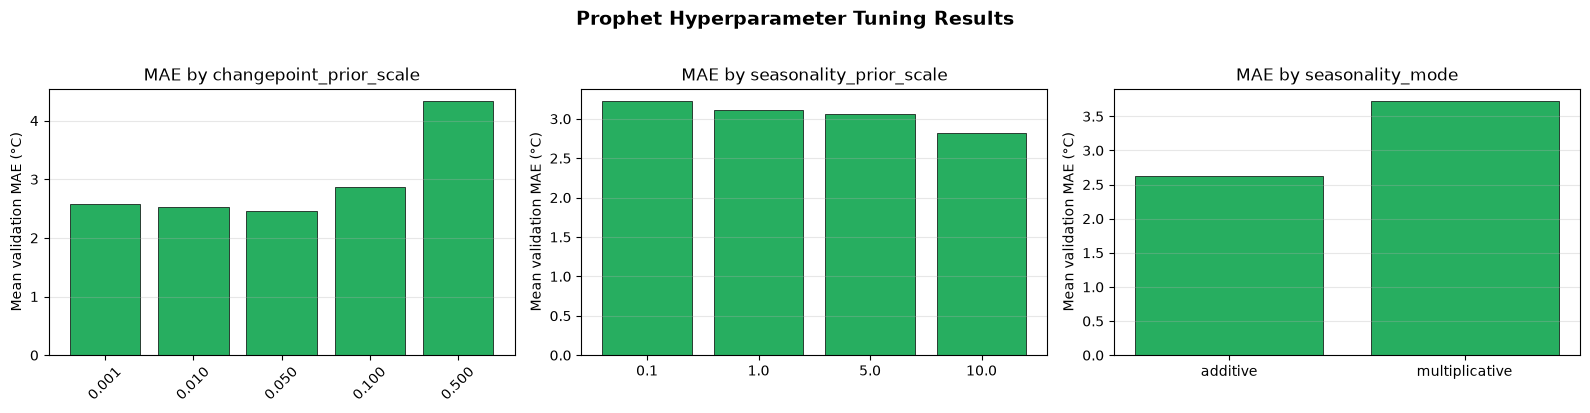


Top 5 Prophet Configurations:
--------------------------------------------------------------------------------
  #1 MAE=2.449°C | cps=0.05, sps=0.1, mode=additive, cr=0.8
  #2 MAE=2.453°C | cps=0.05, sps=5.0, mode=additive, cr=0.9
  #3 MAE=2.478°C | cps=0.05, sps=10.0, mode=multiplicative, cr=0.8
  #4 MAE=2.520°C | cps=0.1, sps=10.0, mode=additive, cr=0.9
  #5 MAE=2.523°C | cps=0.1, sps=5.0, mode=additive, cr=0.8


In [24]:
# Prophet tuning results visualization
results_df = pd.DataFrame([
    {**params, 'MAE': trial_mae} for params, trial_mae in results
])

fig, axes = plt.subplots(1, 3, figsize=(16, 4))

# MAE by changepoint_prior_scale
grouped = results_df.groupby('changepoint_prior_scale')['MAE'].mean()
axes[0].bar(range(len(grouped)), grouped.values, color='#27ae60', edgecolor='black', linewidth=0.5)
axes[0].set_xticks(range(len(grouped)))
axes[0].set_xticklabels([f'{v:.3f}' for v in grouped.index], rotation=45)
axes[0].set_title('MAE by changepoint_prior_scale')
axes[0].set_ylabel('Mean validation MAE (°C)')
axes[0].grid(axis='y', alpha=0.3)

# MAE by seasonality_prior_scale
grouped = results_df.groupby('seasonality_prior_scale')['MAE'].mean()
axes[1].bar(range(len(grouped)), grouped.values, color='#27ae60', edgecolor='black', linewidth=0.5)
axes[1].set_xticks(range(len(grouped)))
axes[1].set_xticklabels([f'{v:.1f}' for v in grouped.index])
axes[1].set_title('MAE by seasonality_prior_scale')
axes[1].set_ylabel('Mean validation MAE (°C)')
axes[1].grid(axis='y', alpha=0.3)

# MAE by seasonality_mode
grouped = results_df.groupby('seasonality_mode')['MAE'].mean()
axes[2].bar(range(len(grouped)), grouped.values, color='#27ae60', edgecolor='black', linewidth=0.5)
axes[2].set_xticks(range(len(grouped)))
axes[2].set_xticklabels(grouped.index)
axes[2].set_title('MAE by seasonality_mode')
axes[2].set_ylabel('Mean validation MAE (°C)')
axes[2].grid(axis='y', alpha=0.3)

plt.suptitle('Prophet Hyperparameter Tuning Results', fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

# Top 5 configurations
print("\nTop 5 Prophet Configurations:")
print("-" * 80)
top5 = sorted(results, key=lambda x: x[1])[:5]
for rank, (params, trial_mae) in enumerate(top5, 1):
    print(f"  #{rank} MAE={trial_mae:.3f}°C | cps={params['changepoint_prior_scale']}, "
          f"sps={params['seasonality_prior_scale']}, "
          f"mode={params['seasonality_mode']}, "
          f"cr={params['changepoint_range']}")

# Stage 11b: Prophet Model Evaluation

In [25]:
# Prophet predictions on test set
prophet_future = df_prophet_test[['ds', 'humidity_mean', 'radiation', 'wind_speed_max', 'precipitation']].copy()
prophet_pred = prophet_model.predict(prophet_future)

y_pred_prophet = prophet_pred['yhat'].values
y_test_prophet = df_prophet_test['y'].values

# Calculate Prophet metrics
prophet_mae = mean_absolute_error(y_test_prophet, y_pred_prophet)
prophet_rmse = np.sqrt(mean_squared_error(y_test_prophet, y_pred_prophet))
prophet_r2 = r2_score(y_test_prophet, y_pred_prophet)
prophet_mape = np.mean(np.abs((y_test_prophet - y_pred_prophet) / (y_test_prophet + 1e-8))) * 100
prophet_smape = np.mean(
    2 * np.abs(y_test_prophet - y_pred_prophet) /
    (np.abs(y_test_prophet) + np.abs(y_pred_prophet) + 1e-8)
) * 100

print("=" * 50)
print("PROPHET EVALUATION RESULTS")
print("=" * 50)
print(f"  MAE:  {prophet_mae:.2f} °C")
print(f"  RMSE: {prophet_rmse:.2f} °C")
print(f"  R²:   {prophet_r2:.4f}")
print(f"  MAPE: {prophet_mape:.2f}%  [supplementary; not used for selection]")
print(f"  sMAPE: {prophet_smape:.2f}%")
print("=" * 50)

PROPHET EVALUATION RESULTS
  MAE:  2.99 °C
  RMSE: 3.79 °C
  R²:   0.8005
  MAPE: 55947364.46%  [supplementary; not used for selection]
  sMAPE: 56.78%


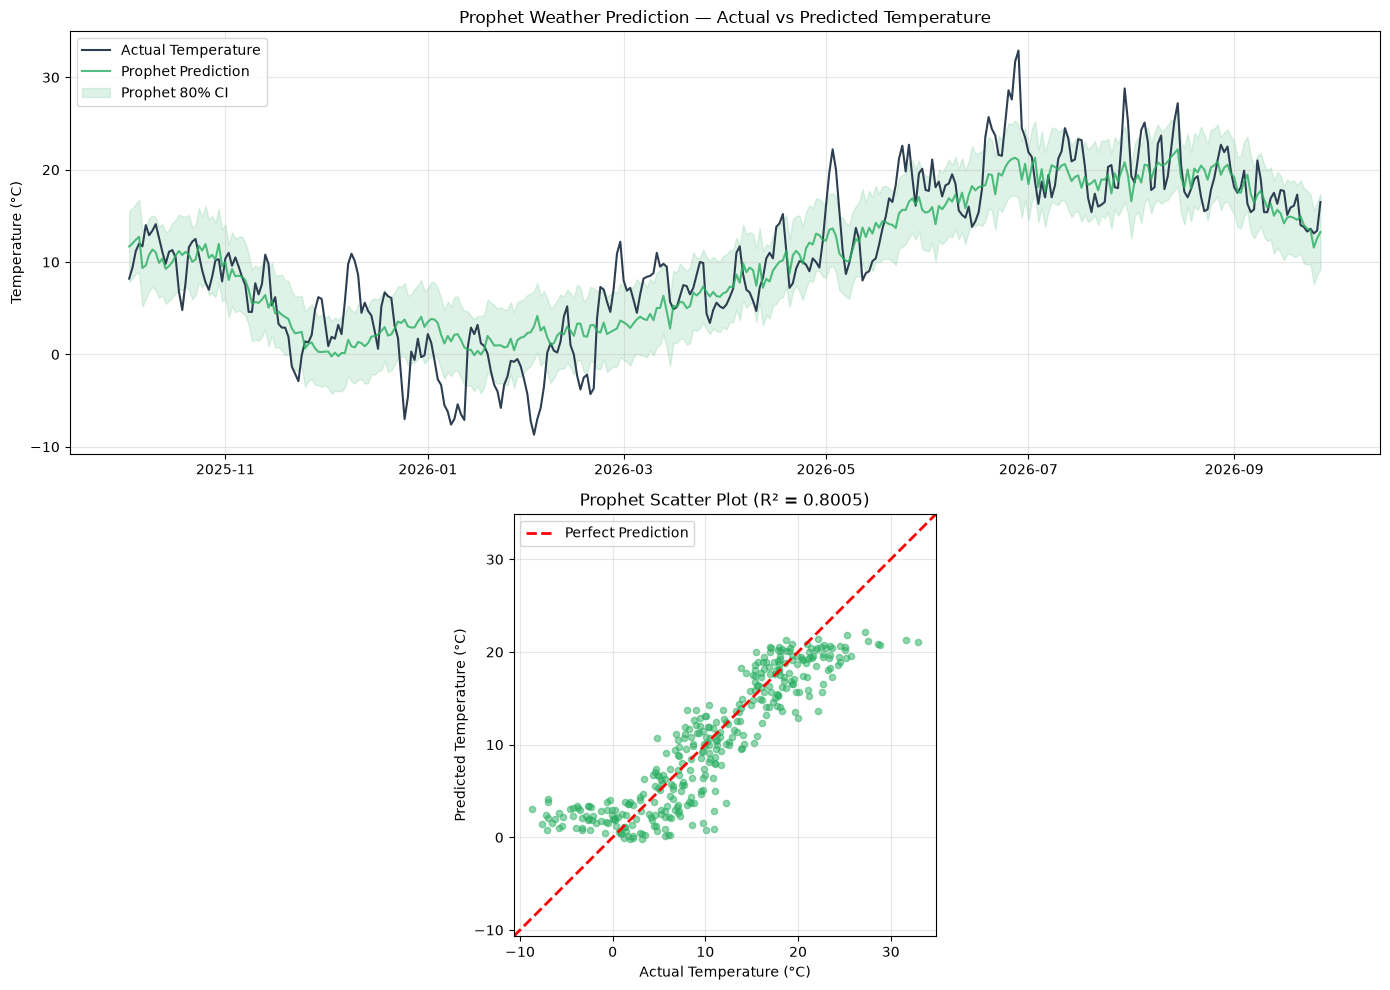

In [26]:
# Prophet: Actual vs Predicted + Components
fig, axes = plt.subplots(2, 1, figsize=(14, 10))

prophet_test_dates = df_prophet_test['ds'].values

axes[0].plot(prophet_test_dates, y_test_prophet, label='Actual Temperature', color='#2c3e50', linewidth=1.5)
axes[0].plot(prophet_test_dates, y_pred_prophet, label='Prophet Prediction', color='#27ae60', linewidth=1.5, alpha=0.8)
axes[0].fill_between(prophet_test_dates,
                     prophet_pred['yhat_lower'].values,
                     prophet_pred['yhat_upper'].values,
                     alpha=0.15, color='#27ae60', label='Prophet 80% CI')
axes[0].set_title('Prophet Weather Prediction — Actual vs Predicted Temperature')
axes[0].set_ylabel('Temperature (°C)')
axes[0].legend(loc='upper left')
axes[0].grid(True, alpha=0.3)

axes[1].scatter(y_test_prophet, y_pred_prophet, alpha=0.5, s=20, color='#27ae60')
min_val = min(y_test_prophet.min(), y_pred_prophet.min()) - 2
max_val = max(y_test_prophet.max(), y_pred_prophet.max()) + 2
axes[1].plot([min_val, max_val], [min_val, max_val], 'r--', linewidth=2, label='Perfect Prediction')
axes[1].set_xlabel('Actual Temperature (°C)')
axes[1].set_ylabel('Predicted Temperature (°C)')
axes[1].set_title(f'Prophet Scatter Plot (R² = {prophet_r2:.4f})')
axes[1].legend()
axes[1].grid(True, alpha=0.3)
axes[1].set_aspect('equal')
axes[1].set_xlim(min_val, max_val)
axes[1].set_ylim(min_val, max_val)

plt.tight_layout()
plt.show()

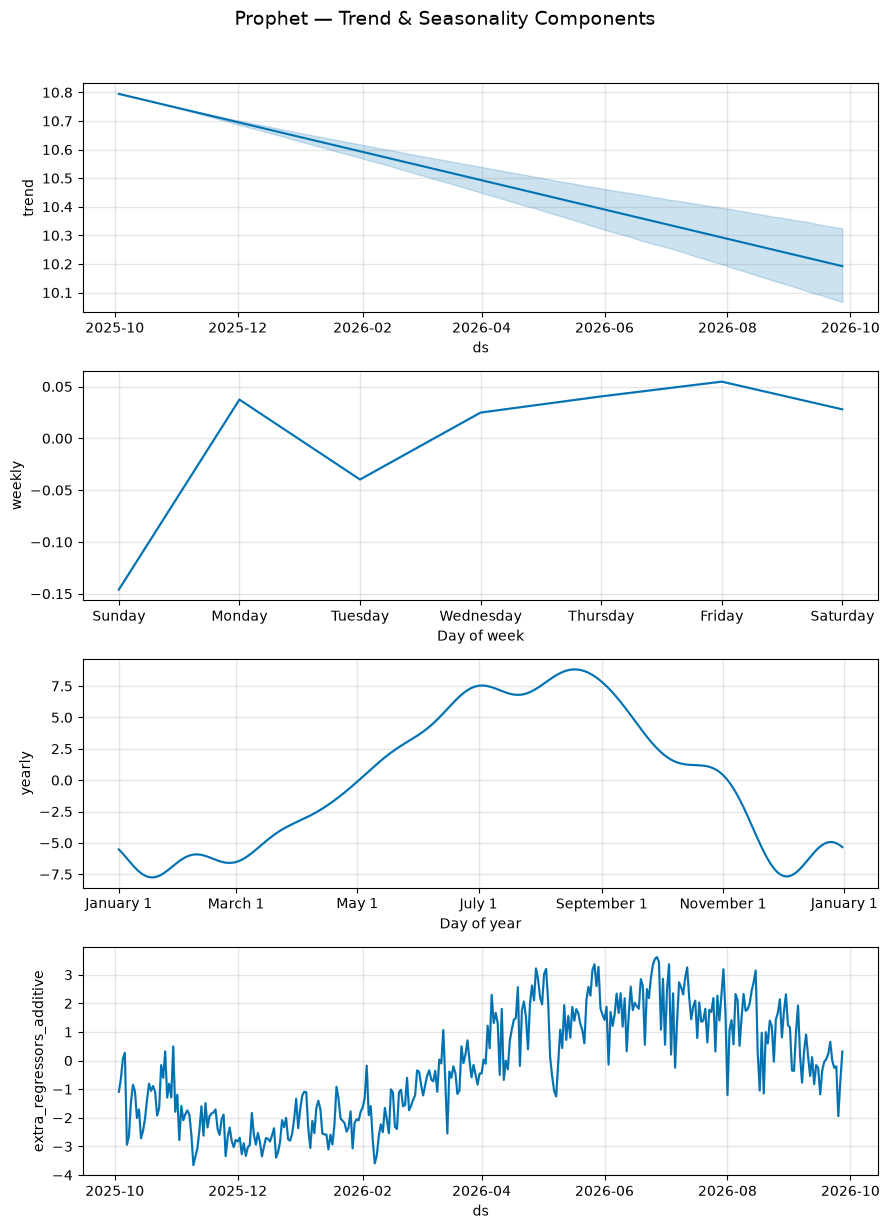

In [27]:
# Prophet trend and seasonality decomposition
fig = prophet_model.plot_components(prophet_pred)
plt.suptitle('Prophet — Trend & Seasonality Components', fontsize=14, y=1.02)
plt.tight_layout()
plt.show()

---

# Stage 12: Three-Model Comparison — LSTM vs Transformer vs Prophet

Side-by-side evaluation of all three models on the same test set, with comparative visualizations and a metrics summary table.

In [28]:
# Three-model comparison metrics table
# V1.1: retain the same three-model comparison, but do not use MAPE
# to select/rank models because it is not appropriate for Celsius values
# around zero.

comparison = pd.DataFrame({
    'Metric': ['MAE (°C)', 'RMSE (°C)', 'R² Score', 'MAPE (%)', 'sMAPE (%)'],
    'LSTM': [
        f'{mae:.2f}', f'{rmse:.2f}', f'{r2:.4f}',
        f'{mape:.2f}', f'{smape:.2f}'
    ],
    'Transformer': [
        f'{trans_mae:.2f}', f'{trans_rmse:.2f}', f'{trans_r2:.4f}',
        f'{trans_mape:.2f}', f'{trans_smape:.2f}'
    ],
    'Prophet': [
        f'{prophet_mae:.2f}', f'{prophet_rmse:.2f}', f'{prophet_r2:.4f}',
        f'{prophet_mape:.2f}', f'{prophet_smape:.2f}'
    ]
})
comparison.set_index('Metric', inplace=True)

print("=" * 75)
print("       LSTM vs TRANSFORMER vs PROPHET — COMPARISON TABLE")
print("=" * 75)
print(comparison.to_string())
print("=" * 75)

print("\nPrimary metrics for interpretation: MAE, RMSE and R².")
print("MAPE is retained only for continuity with V1 and should not be interpreted as a reliable")
print("temperature-forecasting metric. sMAPE is reported as an additional supplementary metric.")


       LSTM vs TRANSFORMER vs PROPHET — COMPARISON TABLE
                  LSTM  Transformer      Prophet
Metric                                          
MAE (°C)          1.55         1.57         2.99
RMSE (°C)         2.01         2.06         3.79
R² Score        0.9438       0.9412       0.8005
MAPE (%)   41826187.84  54022729.51  55947364.46
sMAPE (%)        30.12        30.65        56.78

Primary metrics for interpretation: MAE, RMSE and R².
MAPE is retained only for continuity with V1 and should not be interpreted as a reliable
temperature-forecasting metric. sMAPE is reported as an additional supplementary metric.


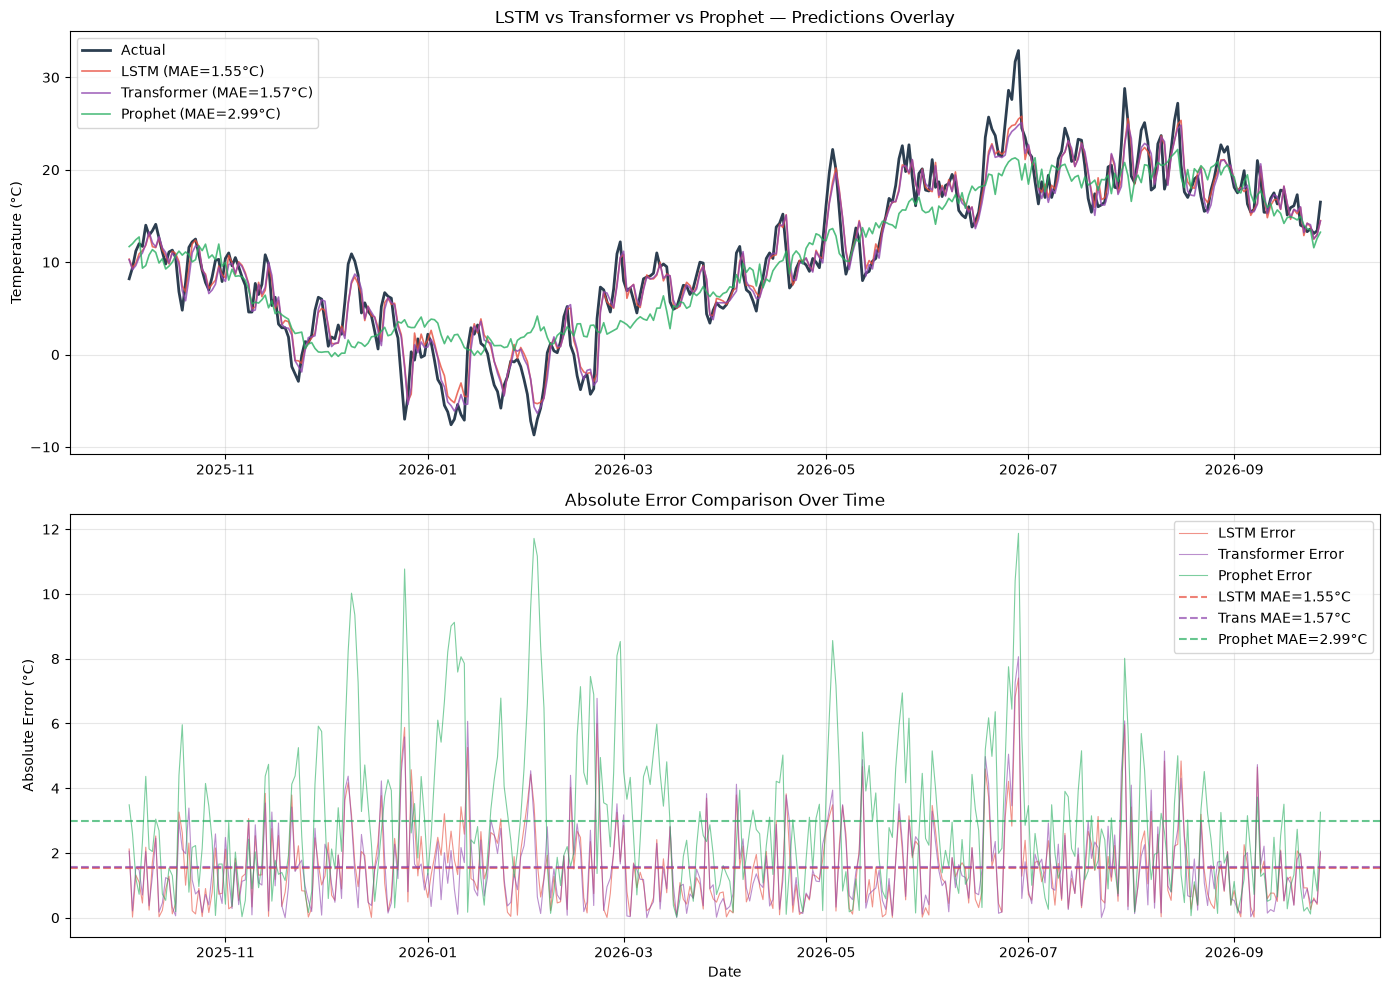

In [29]:
# Visual comparison: all three predictions overlaid
fig, axes = plt.subplots(2, 1, figsize=(14, 10))

# Predictions overlay
axes[0].plot(test_dates, y_test_actual, label='Actual', color='#2c3e50', linewidth=2)
axes[0].plot(test_dates, y_pred_actual, label=f'LSTM (MAE={mae:.2f}°C)', color='#e74c3c',
             linewidth=1.2, alpha=0.8)
axes[0].plot(test_dates, y_pred_transformer, label=f'Transformer (MAE={trans_mae:.2f}°C)',
             color='#8e44ad', linewidth=1.2, alpha=0.8)
axes[0].plot(prophet_test_dates, y_pred_prophet, label=f'Prophet (MAE={prophet_mae:.2f}°C)',
             color='#27ae60', linewidth=1.2, alpha=0.8)
axes[0].set_title('LSTM vs Transformer vs Prophet — Predictions Overlay')
axes[0].set_ylabel('Temperature (°C)')
axes[0].legend(loc='upper left')
axes[0].grid(True, alpha=0.3)

# Absolute error comparison
lstm_abs_error = np.abs(y_test_actual - y_pred_actual)
trans_abs_error = np.abs(y_test_actual - y_pred_transformer)
prophet_abs_error = np.abs(y_test_prophet - y_pred_prophet)

axes[1].plot(test_dates, lstm_abs_error, label='LSTM Error', color='#e74c3c', alpha=0.6, linewidth=0.8)
axes[1].plot(test_dates, trans_abs_error, label='Transformer Error', color='#8e44ad', alpha=0.6, linewidth=0.8)
axes[1].plot(prophet_test_dates, prophet_abs_error, label='Prophet Error', color='#27ae60', alpha=0.6, linewidth=0.8)
axes[1].axhline(y=mae, color='#e74c3c', linestyle='--', alpha=0.7, label=f'LSTM MAE={mae:.2f}°C')
axes[1].axhline(y=trans_mae, color='#8e44ad', linestyle='--', alpha=0.7, label=f'Trans MAE={trans_mae:.2f}°C')
axes[1].axhline(y=prophet_mae, color='#27ae60', linestyle='--', alpha=0.7, label=f'Prophet MAE={prophet_mae:.2f}°C')
axes[1].set_title('Absolute Error Comparison Over Time')
axes[1].set_xlabel('Date')
axes[1].set_ylabel('Absolute Error (°C)')
axes[1].legend(loc='upper right')
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

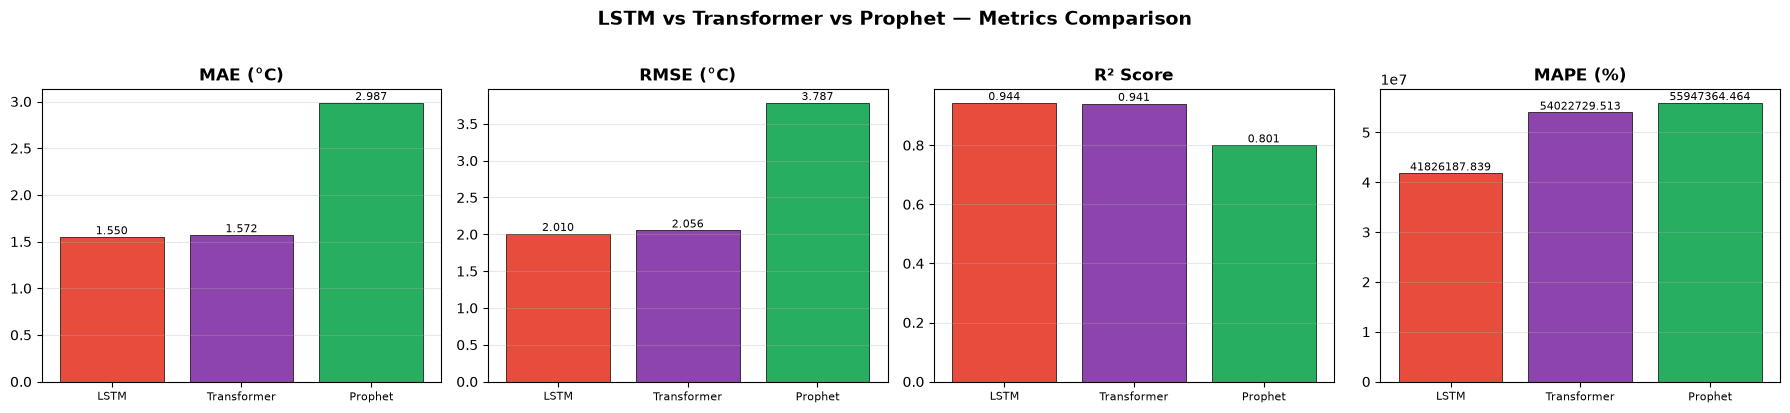

In [30]:
# Bar chart comparison of metrics — 3 models
fig, axes = plt.subplots(1, 4, figsize=(18, 4))

metrics_names = ['MAE (°C)', 'RMSE (°C)', 'R² Score', 'MAPE (%)']
lstm_vals = [mae, rmse, r2, mape]
trans_vals = [trans_mae, trans_rmse, trans_r2, trans_mape]
prophet_vals = [prophet_mae, prophet_rmse, prophet_r2, prophet_mape]

colors = ['#e74c3c', '#8e44ad', '#27ae60']
labels = ['LSTM', 'Transformer', 'Prophet']

for i, (name, lv, tv, pv) in enumerate(zip(metrics_names, lstm_vals, trans_vals, prophet_vals)):
    vals = [lv, tv, pv]
    bars = axes[i].bar(labels, vals, color=colors, edgecolor='black', linewidth=0.5)
    axes[i].set_title(name, fontweight='bold')
    axes[i].bar_label(bars, fmt='%.3f', fontsize=8)
    axes[i].grid(axis='y', alpha=0.3)
    axes[i].tick_params(axis='x', labelsize=8)

    # No winner is highlighted: MAPE is not an appropriate
    # primary metric for Celsius temperature, and V1.1 avoids
    # reducing the comparison to a single overall ranking.


plt.suptitle('LSTM vs Transformer vs Prophet — Metrics Comparison', fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

  7-DAY TEMPERATURE FORECAST — BERLIN (All Models)
  Date                       LSTM    Transformer    Prophet
---------------------------------------------------------------------------
  Mon 05 Oct 2026          15.4 °C         15.9 °C     11.3 °C
  Tue 06 Oct 2026          15.8 °C         16.0 °C     11.1 °C
  Wed 07 Oct 2026          16.1 °C         16.0 °C     11.1 °C
  Thu 08 Oct 2026          16.3 °C         16.0 °C     11.1 °C
  Fri 09 Oct 2026          16.2 °C         15.9 °C     11.0 °C
  Sat 10 Oct 2026          15.9 °C         15.8 °C     10.9 °C
  Sun 11 Oct 2026          15.6 °C         15.7 °C     10.7 °C


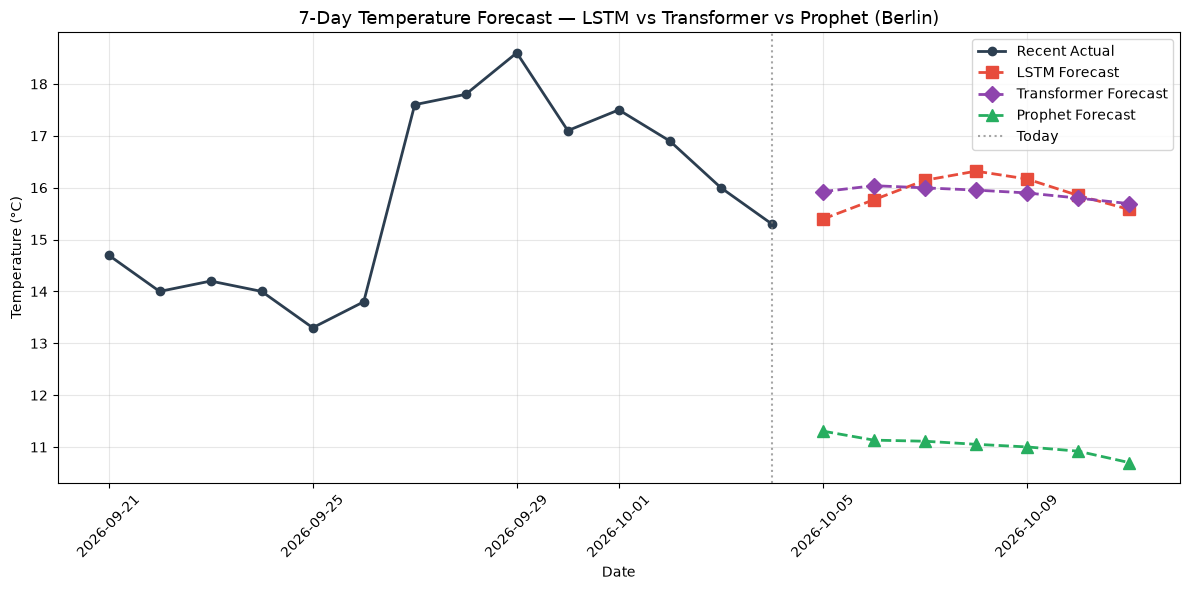

In [31]:
# All three models: 7-day live forecast
transformer_forecast = forecast_next_days(transformer_model, scaler, target_scaler, recent_scaled, n_days=7)

# Prophet forecast — needs a future dataframe with regressors
# Use the last known values for regressors (persistence assumption for forecast period)
prophet_future_dates = pd.DataFrame({
    'ds': forecast_dates,
    'humidity_mean': [df_recent['humidity_mean'].iloc[-1]] * 7,
    'radiation': [df_recent['radiation'].iloc[-1]] * 7,
    'wind_speed_max': [df_recent['wind_speed_max'].iloc[-1]] * 7,
    'precipitation': [df_recent['precipitation'].iloc[-1]] * 7
})
prophet_live_pred = prophet_model.predict(prophet_future_dates)
prophet_forecast = prophet_live_pred['yhat'].values

print("=" * 75)
print("  7-DAY TEMPERATURE FORECAST — BERLIN (All Models)")
print("=" * 75)
print(f"  {'Date':<20} {'LSTM':>10} {'Transformer':>14} {'Prophet':>10}")
print("-" * 75)
for date, lt, tt, pt in zip(forecast_dates, lstm_forecast, transformer_forecast, prophet_forecast):
    print(f"  {date.strftime('%a %d %b %Y'):<20} {lt:>8.1f} °C {tt:>12.1f} °C {pt:>8.1f} °C")
print("=" * 75)

# Plot all three forecasts
fig, ax = plt.subplots(figsize=(12, 6))
ax.plot(df_recent.index[-14:], df_recent['temp_mean'].values[-14:],
        'o-', color='#2c3e50', label='Recent Actual', linewidth=2, markersize=6)
ax.plot(forecast_dates, lstm_forecast,
        's--', color='#e74c3c', label='LSTM Forecast', linewidth=2, markersize=8)
ax.plot(forecast_dates, transformer_forecast,
        'D--', color='#8e44ad', label='Transformer Forecast', linewidth=2, markersize=8)
ax.plot(forecast_dates, prophet_forecast,
        '^--', color='#27ae60', label='Prophet Forecast', linewidth=2, markersize=8)
ax.axvline(x=df_recent.index[-1], color='gray', linestyle=':', alpha=0.7, label='Today')
ax.set_title('7-Day Temperature Forecast — LSTM vs Transformer vs Prophet (Berlin)', fontsize=13)
ax.set_xlabel('Date')
ax.set_ylabel('Temperature (°C)')
ax.legend()
ax.grid(True, alpha=0.3)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# V1.1 Methodological Corrections

This version deliberately preserves the original V1 experimental design rather than replacing it with a new forecasting framework.

### Preserved from V1
- Berlin and the Open-Meteo data source
- the original meteorological variables
- the 30-day lookback
- 80/20 chronological train/test split
- Bidirectional LSTM
- Transformer
- Prophet
- Keras Tuner Hyperband
- one-step neural-network training followed by recursive 7-day forecasting
- the original visualisation structure

### Corrections made
1. **Scaling leakage:** MinMaxScaler and the target scaler are fitted only on the training period.
2. **Prophet tuning leakage:** Prophet hyperparameters are selected using a chronological validation subset inside the training period, then the selected model is refit on the full training period before final test evaluation.
3. **MAPE interpretation:** MAPE is retained for continuity with V1 but explicitly treated as supplementary because Celsius temperature can be zero or negative. MAE, RMSE and R² remain the principal metrics; sMAPE is added as a supplementary metric.
4. **Model comparison:** the V1 three-model comparison is retained without an artificial overall winner based on counting metric wins.


# Stage 13: Conclusion

## Summary

- Built and compared **three models** — Bidirectional LSTM, Transformer, and Facebook Prophet — to predict daily mean temperature for Berlin
- Used **2 years of historical weather data** from the Open-Meteo API with 10 meteorological features + 4 cyclical temporal features
- Applied **Keras Tuner Hyperband search** for LSTM and Transformer hyperparameter optimisation
- Prophet serves as a **statistical baseline** with trend and seasonality modelling
- Preserved the original V1 one-step neural forecasting strategy with recursive 7-day forecasting

## Methodological corrections in V1.1

- Feature and target scaling is fitted only on the training period
- Prophet hyperparameters are selected on a validation subset of the training period rather than the final test set
- MAE, RMSE and R² remain the principal evaluation metrics
- MAPE is retained only for continuity with V1 and is not interpreted as a reliable temperature metric
- sMAPE is reported as an additional supplementary metric

## Key Findings

Complete this section **only after running the V1.1 notebook**. Report the observed MAE, RMSE and R² for each model and describe the differences under this specific Berlin dataset and experimental setup.

## Limitations & Future Work

- Autoregressive forecasting can accumulate error across the seven recursive prediction steps
- Prophet currently uses meteorological regressors; for real-world deployment, future regressor values would need to be forecast or otherwise known in advance
- The dataset covers approximately two years, limiting the amount of historical information available to the models
- Additional variables such as cloud cover, surface pressure and dewpoint could be investigated
- Larger datasets and alternative forecasting strategies could be examined in future work
